<a href="https://colab.research.google.com/github/Hasnat22/DailyTasks/blob/main/Week5_Workshop_Pandas_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Risk — Exploratory Data Analysis (EDA)
### CMP7005 · Studio teaching notebook · Research-question-led analysis

In this session, **we will explore the diabetes dataset together** and use the findings to understand how to plan an EDA investigation. You will apply the same process, not necessarily the same variables or charts, to the **hypertension dataset** for PRAC1.

**Our EDA sequence:** Research motivation → data understanding → data quality → data cleaning → feature engineering → univariate analysis → bivariate analysis → multivariate analysis → findings and limitations.

We will demonstrate **Pandas, Matplotlib and Plotly**, including several ways of creating related charts. Similar charts are retained deliberately so that you can compare the libraries and choose suitable visualisations for your own analysis.

**Assessment connection:** PRAC1 Task 1 asks for 3–4 research questions; Tasks 2a–2c require data understanding, justified cleaning, feature engineering, and meaningful statistical analysis and interpretation. Our charts describe associations; they are not diagnostic tools.

**Using this notebook:** Run cells in order. The discussion paragraphs that refer to saved results are from the uploaded original notebook and must be checked against outputs if you work with a changed dataset.

## Stage 0 — Research motivation (PRAC1 Task 1)

Before we calculate anything, we need questions that give our investigation a purpose. These are our **four initial research questions**:

**RQ1 — Demographic characteristics:** How does diabetes risk classification differ by **age** and **gender**?

**RQ2 — Lifestyle factors:** How does diabetes risk classification vary with **physical activity, diet quality, sleep duration, smoking, stress**, and **family history of diabetes**?

**RQ3 — Clinical measurements:** How do **BMI, fasting glucose, HbA1c, cholesterol**, and related numerical variables differ between the `Yes` and `No` diabetes-risk groups?

**RQ4 — Combined patterns:** What relationships exist among **BMI, waist circumference, fasting glucose, HbA1c and age**, and do the patterns differ by diabetes-risk group?

We will begin with general quality checks, then refer back to these questions during univariate, bivariate and multivariate EDA. **Research questions guide our investigation but do not restrict new findings.**

**For your PRAC1:** Write 3–4 *hypertension* questions using your dataset and decide which comparisons could answer them. The brief asks you to go beyond the original questions when an important new pattern emerges.


# Diabetes Risk Dataset — Exploratory Data Analysis (EDA)

This notebook focuses **only on data analysis and visualisation**. It does **not** build any prediction or machine-learning model.

### What we will do
- Understand the dataset
- Check missing values and duplicates
- Perform simple data cleaning
- Explore individual variables
- Compare categorical variables
- Explore relationships between numerical variables
- Compare numerical variables with diabetes risk
- Create a correlation heatmap
- Summarise the main patterns

The code is intentionally kept simple for teaching and beginner practice.


## Import the libraries

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

import numpy as np  # Needed for the grouped numerical bar charts

## Setup
Run the import cell, then load the CSV. In Google Colab, upload the file or ensure your cloned repository contains it.

### Data file setup
 **Clone** your own GitHub repository containing that CSV, and update the filename/path below to match its location. Do not run an unrelated repository clone.

For this teaching notebook, we use the attached diabetes dataset. Students use their hypertension dataset for PRAC1.

## Setup
Run the import cell, then load the CSV. In Google Colab, upload the file or ensure your cloned repository contains it.

In [4]:
username = "Hasnat22"
repo = "hypertension_dataset"
!git clone https://github.com/Hasnat22/hypertension_dataset.git
%cd {repo}
%ls

Cloning into 'hypertension_dataset'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 18 (delta 8), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 149.04 KiB | 2.76 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/hypertension_dataset
'hypertension_dataset_5000 (1).csv'   Week5_Workshop_Pandas_Student.ipynb


In [8]:
# Load the supplied diabetes CSV file
# In Colab, upload diabetes_risk(1).csv first, or update this path to your repository.
df = pd.read_csv('/content/hypertension_dataset_5000.csv')
df.head()

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
0,83.2,Male,24.6,92.5,Normal,Light,NaN,Former,Moderate,7.5,No,0.98,89.0,201.4,119,65,Normal,No
1,69.0,Female,26.1,76.6,Very High,Light,NaN,Former,Low,6.5,Yes,NaN,83.2,178.9,132,81,Stage 1 Hypertension,Yes
2,45.1,Male,24.5,86.4,High,Sedentary,Occasional,Former,Very High,6.1,No,1.02,86.0,163.2,131,87,Stage 1 Hypertension,Yes
3,45.5,Male,25.6,85.2,Normal,Active,Moderate,Current,High,6.4,Yes,0.86,80.5,146.0,127,88,Stage 1 Hypertension,Yes
4,41.7,Male,28.7,97.4,High,Active,Moderate,Current,High,6.9,No,1.27,97.0,210.6,120,78,Elevated,No


## Stage 1 — Data understanding | PRAC1 Task 2a
Inspect the sample, shape, column names, types and numerical summaries **before modifying the data**. Note what the outcome means and whether any variables might be related to how it was defined.



**Why this stage matters:** We need to know our variables and population before deciding which analysis can answer RQ1–RQ4.

## Understand the dataset

In [9]:
# Number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 5000
Number of columns: 18


In [10]:

# Column names
df.columns


Index(['Age', 'Gender', 'BMI', 'Waist_Circumference_cm', 'Salt_Intake',
       'Physical_Activity', 'Alcohol_Consumption', 'Smoking_Status',
       'Stress_Level', 'Sleep_Hours', 'Family_History_HTN', 'Creatinine_mg_dL',
       'Fasting_Glucose_mg_dL', 'Cholesterol_mg_dL', 'Systolic_BP_mmHg',
       'Diastolic_BP_mmHg', 'BP_Category', 'Hypertension'],
      dtype='object')

In [11]:

# Data types and non-missing values
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     5000 non-null   float64
 1   Gender                  5000 non-null   object 
 2   BMI                     5000 non-null   float64
 3   Waist_Circumference_cm  4846 non-null   float64
 4   Salt_Intake             4939 non-null   object 
 5   Physical_Activity       5000 non-null   object 
 6   Alcohol_Consumption     3632 non-null   object 
 7   Smoking_Status          5000 non-null   object 
 8   Stress_Level            4909 non-null   object 
 9   Sleep_Hours             4837 non-null   float64
 10  Family_History_HTN      5000 non-null   object 
 11  Creatinine_mg_dL        4867 non-null   float64
 12  Fasting_Glucose_mg_dL   4821 non-null   float64
 13  Cholesterol_mg_dL       4841 non-null   float64
 14  Systolic_BP_mmHg        5000 non-null   

In [12]:
cat_cols=df.select_dtypes(include=['object']).columns
num_cols = df.select_dtypes(include='number').columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print('\n')
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
Index(['Gender', 'Salt_Intake', 'Physical_Activity', 'Alcohol_Consumption',
       'Smoking_Status', 'Stress_Level', 'Family_History_HTN', 'BP_Category',
       'Hypertension'],
      dtype='object')


Numerical Variables:
['Age', 'BMI', 'Waist_Circumference_cm', 'Sleep_Hours', 'Creatinine_mg_dL', 'Fasting_Glucose_mg_dL', 'Cholesterol_mg_dL', 'Systolic_BP_mmHg', 'Diastolic_BP_mmHg']


In [13]:

# Basic statistical summary of numerical variables
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,5000.0,48.648320,16.908037,18.20,34.575,47.40,61.60,89.20
BMI,5000.0,27.876320,4.254628,16.20,24.900,27.70,30.80,43.50
Waist_Circumference_cm,4846.0,89.417623,11.410790,54.00,81.500,89.10,97.10,126.40
Sleep_Hours,4837.0,6.850444,1.042016,3.50,6.200,6.90,7.50,10.50
Creatinine_mg_dL,4867.0,0.942063,0.171618,0.51,0.820,0.93,1.05,1.68
Fasting_Glucose_mg_dL,4821.0,93.301058,12.753358,62.10,84.500,92.20,100.90,173.40
Cholesterol_mg_dL,4841.0,187.219851,30.546704,105.00,165.600,187.30,207.60,288.30
Systolic_BP_mmHg,5000.0,116.826600,16.385269,88.00,104.000,115.00,128.00,181.00
Diastolic_BP_mmHg,5000.0,74.259600,9.483849,50.00,67.000,74.00,81.00,110.00


### Interpretation of Descriptive Statistics

The descriptive statistics provide an initial overview of the numerical variables in the diabetes risk dataset, including their central tendency, variability and range.

**Key observations:**

1. **Age:** The average age is approximately 46 years, with patients ranging from 18 to 90 years. The standard deviation of 14.57 indicates considerable variation in patient ages.

2. **BMI:** The mean BMI is 27.12, with a median of 27.10. This falls within the conventional overweight category. BMI ranges from 15.0 to 47.3, indicating substantial variation in body composition.

3. **Waist Circumference:** The average waist circumference is 74.16 cm, ranging from 55.0 to 135.2 cm. Only 7,868 of the 8,045 records contain valid measurements, indicating missing values.

4. **Lifestyle Variables:** Patients report an average of 6.79 hours of sleep and 5.49 hours of screen time per day. Sleep duration ranges from 3 to 11 hours, while screen time ranges from 0 to 13.7 hours. These differences may be worth investigating in relation to diabetes risk.

5. **Clinical Measurements:** Average cholesterol is 197.59 mg/dL, average fasting glucose is 90.24 mg/dL, and average systolic blood pressure is 123.41 mmHg. However, the wide ranges suggest that some patients have substantially higher measurements than others.

6. **HbA1c:** The average HbA1c is 4.22%, with values ranging from 3.8% to 5.97%. The relatively small standard deviation (0.40) indicates less variation than in several other numerical variables.

7. **Missing Values:** Waist circumference, sleep hours, screen time, cholesterol and insulin level have fewer than 8,045 non-null observations. These variables require further investigation during the data-quality assessment.

### Overall Inference

The dataset contains patients with varied demographic, lifestyle and clinical characteristics. Differences in age, BMI, sleep duration, fasting glucose and other measurements provide opportunities to investigate factors associated with diabetes risk.

However, descriptive statistics alone cannot establish relationships between these variables and diabetes risk. Further **univariate, bivariate and multivariate analyses** are needed to understand their distributions and associations with the outcome variable.

**Next step:** Examine the numerical distributions using histograms and box plots to identify skewness, potential outliers and unusual patterns before proceeding to group comparisons.

## Stage 2 — Data-quality assessment | PRAC1 Task 2a
Investigate **missing values, duplicates, inconsistent categories and unusual numerical observations** before deciding how to clean. The original notebook's checks are preserved below. An IQR count is an *initial flag*, not proof of an error.

**Before using the risk comparisons**, check missingness and coding quality. They can affect any of RQ1–RQ4.

## Check data quality

**Verified labels and duplicates:** The original dataset contains **45 exact duplicate rows** and six raw gender labels (`Female`, `Male`, `male`, `F`, `female`, `M`). We standardise these to `Female` and `Male` before comparisons. Removing the 45 duplicate records leaves **8,000 observations**. The removal should be explained as a preprocessing decision.

In [14]:

# Count missing values in each column
missing_values = df.isnull().sum()
missing_values.name = "Missing Values"

missing_values


,Missing Values
Age,0
Gender,0
BMI,0
Waist_Circumference_cm,154
Salt_Intake,61
Physical_Activity,0
Alcohol_Consumption,1368
Smoking_Status,0
Stress_Level,91
Sleep_Hours,163


In [15]:
# Display missing values
print("Missing Values:")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing_Count': missing,
    'Percentage': missing_pct
})
(missing_df[missing_df['Missing_Count'] > 0].sort_values('Percentage', ascending=False))

Missing Values:


,Missing_Count,Percentage
Alcohol_Consumption,1368,27.36
Fasting_Glucose_mg_dL,179,3.58
Sleep_Hours,163,3.26
Cholesterol_mg_dL,159,3.18
Waist_Circumference_cm,154,3.08
Creatinine_mg_dL,133,2.66
Stress_Level,91,1.82
Salt_Intake,61,1.22


**Verified data-quality findings:** In the original 8,045-row CSV, `Alcohol_Consumption` has **2,783 missing values (34.59%)**, followed by `Insulin_Level` with **328 (4.08%)** and `Cholesterol_mg_dL` with **258 (3.21%)**. Missing alcohol responses are **not** the same as the existing category `None` (non-drinkers). The cleaning code uses `Unknown` to distinguish missing information.

In [ ]:

# Counting duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 45


In [ ]:
# Let's look at the different Gender labels
df["Gender"].value_counts()


,count
Gender,
Female,3319
Male,3085
male,423
F,417
female,412
M,389


### Additional data-quality check — possible numerical outliers (IQR)
This short check complements the original missing-value and duplicate checks. Record columns requiring further examination; do not automatically delete unusual clinical measurements.

In [ ]:
# Identify possible outliers in numerical columns using the IQR rule
outlier_results = []
for col in df.select_dtypes(include='number').columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    count = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    outlier_results.append([col, count])

pd.DataFrame(outlier_results, columns=['Column', 'Possible outliers'])

,Column,Possible outliers
0,Age,35
1,BMI,32
2,Waist_Circumference_cm,35
3,Sleep_Hours,47
4,Screen_Time_Hours,22
5,Cholesterol_mg_dL,28
6,Blood_Pressure_Systolic_mmHg,19
7,Insulin_Level,23
8,Fasting_Glucose_mg_dL,34
9,HbA1c_percent,30


In [ ]:
# Add the outlier percentage, and flag columns if more than 1% of rows are unusual
outlier_summary = []
for col in df.select_dtypes(include='number').columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    pct = n_out / len(df) * 100
    outlier_summary.append([col, n_out, round(pct, 2), 'CHECK' if pct > 1 else 'Below 1%'])

outlier_table = pd.DataFrame(outlier_summary,
                             columns=['Variable', 'IQR outliers', 'Percent (%)', 'Flag'])
display(outlier_table.sort_values('IQR outliers', ascending=False))

,Variable,IQR outliers,Percent (%),Flag
3,Sleep_Hours,47,0.58,Below 1%
0,Age,35,0.44,Below 1%
2,Waist_Circumference_cm,35,0.44,Below 1%
8,Fasting_Glucose_mg_dL,34,0.42,Below 1%
1,BMI,32,0.40,Below 1%
9,HbA1c_percent,30,0.37,Below 1%
5,Cholesterol_mg_dL,28,0.35,Below 1%
7,Insulin_Level,23,0.29,Below 1%
4,Screen_Time_Hours,22,0.27,Below 1%
6,Blood_Pressure_Systolic_mmHg,19,0.24,Below 1%


**How to interpret the IQR check:** Values beyond Q1 − 1.5 × IQR or Q3 + 1.5 × IQR are *potential* outliers. The table above calculates the counts from the file you load. The IQR rule is not a medical validity test; do not remove extreme glucose or BMI readings automatically. Inspect plausible ranges and document any decision for PRAC1 Task 2a/2b.

**Interpretation:** The most IQR outliers occur in `Sleep_Hours` (47; 0.58%). `Fasting_Glucose_mg_dL` has 34 (0.42%). **No numerical column exceeds 1%** of the 8,045 rows, so the 1% flag correctly shows no `CHECK` entries.

**Brief reflection (2a):** Which issues are likely to affect analysis? Are the values genuinely wrong, simply rare, or missing for a reason? Note any inconsistent labels, not just missing counts.

## Stage 3 — Data preprocessing | PRAC1 Task 2b


**Important clinical distinction:** Missing alcohol-consumption information is not equivalent to a patient who reports *no alcohol consumption*. In this teaching notebook, `Unknown` keeps that difference visible. Median imputation is a simple illustration, not a universal best choice. The assessment requires a justification for each decision. Do **not** standardise, normalise or scale for this EDA assessment.

**Assessment link:** Justify how your choices change the data. Do not treat filling or removing values as automatic.


## Data cleaning

For this we will:
- remove duplicate rows;
- standardise the Gender labels;
- replace missing categorical values with `Unknown`;
- replace missing numerical values with the median of that column.

This gives us a complete dataset that is easy to use for the visualisations below.


In [ ]:

# Making a copy before cleaning
data = df.copy()

In [ ]:
# Checking how many duplicate rows there are
df.duplicated().sum()

np.int64(45)

In [ ]:

# Standardise Gender labels
# Convert all text to lower case first

data["Gender"] = data["Gender"].str.lower()

# Replace different forms with a common label
data["Gender"] = data["Gender"].replace({
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female"
})

print(data["Gender"].value_counts(dropna=False))


Gender
Female    4148
Male      3897
Name: count, dtype: int64


link for understanding the different imputation techniques: https://towardsdatascience.com/missing-value-imputation-explained-a-visual-guide-with-code-examples-for-beginners-93e0726284eb/

In [ ]:

# Find categorical and numerical columns
categorical_columns = data.select_dtypes(include="object").columns
numerical_columns = data.select_dtypes(include="number").columns

# Fill missing categorical values with 'Unknown'
for column in categorical_columns:
    data[column] = data[column].fillna("Unknown")

# Fill missing numerical values with the median
for column in numerical_columns:
    data[column] = data[column].fillna(data[column].median())

# Check missing values again
print(data.isnull().sum())


Age                             0
Gender                          0
BMI                             0
Waist_Circumference_cm          0
Diet_Quality                    0
Physical_Activity               0
Alcohol_Consumption             0
Smoking_Status                  0
Sleep_Hours                     0
Screen_Time_Hours               0
Stress_Level                    0
Family_History_Diabetes         0
Cholesterol_mg_dL               0
Blood_Pressure_Systolic_mmHg    0
Insulin_Level                   0
Fasting_Glucose_mg_dL           0
HbA1c_percent                   0
Risk_Category                   0
Diabetes_Risk                   0
dtype: int64


### Verify the cleaning decisions
The original notebook checks duplicate counts but does not actually remove duplicate rows. If duplicates are confirmed as unwanted records, the following extra example shows how to remove them on the **copy**. If duplication is legitimate, do not remove it automatically.

In [ ]:
# Remove exact duplicate records only when justified
print('Duplicate rows before:', data.duplicated().sum())
data = data.drop_duplicates().copy()
print('Duplicate rows after:', data.duplicated().sum())
print('Remaining missing values:', data.isnull().sum().sum())

Duplicate rows before: 45
Duplicate rows after: 0
Remaining missing values: 0


**What changed during cleaning?** Exact duplicates were removed, gender labels were standardised, missing categorical values were labelled `Unknown`, and missing numerical values were filled with medians. This is a **teaching demonstration**—in your assessment you must justify each variable-specific decision. Note that removing duplicates **after** median imputation could change which rows are regarded as exact duplicates; compare against raw duplicates too.

In [ ]:
# Final basic checks on the cleaned dataset
print('Cleaned rows:', len(data))
print('Remaining missing values:', data.isna().sum().sum())
print('Gender labels:', data['Gender'].unique())

Cleaned rows: 8000
Remaining missing values: 0
Gender labels: ['Female' 'Male']


## Stage 4 — Meaningful feature engineering | PRAC1 Task 2b
These **existing** age-group and BMI-category examples demonstrate how categories can help compare groups. They are included before the visual EDA sections because the derived columns are created here.

**Interpretation:** Explain the chosen boundaries and recognise that binning a continuous variable loses detail. For hypertension, the brief explicitly asks students to consider clinically meaningful derived measures from systolic/diastolic pressure, including whether those measurements define the target. Do not copy diabetes feature names blindly.

**Research-question link:** Age groups support RQ1; BMI categories support RQ3. Retain the original numerical columns so we do not lose information.

## AGE GROUP ANALYSIS - Column Charts

In [ ]:
# ==========================================================
# Step 1 — Create Age Groups
# ==========================================================

import plotly.express as px

# Create a new categorical column called 'Age_Group'
# pd.cut() divides the continuous Age variable into different age intervals
data['Age_Group'] = pd.cut(
    data['Age'],                         # Numerical column to be grouped
    bins=[0, 30, 40, 50, 60, 100],       # Define the boundaries of each age group
    labels=['18-30', '30-40', '40-50', '50-60', '60+']  # Labels for each group
)


# ==========================================================
# Step 2 — Bar Chart: Distribution by Age Group
# ==========================================================

# Count the number of patients in each age group
# value_counts() calculates the frequency of each group
# sort_index() arranges the groups in their original age order
# reset_index() converts the result into a DataFrame for Plotly
age_counts = data['Age_Group'].value_counts().sort_index().reset_index()

# Create an interactive bar chart
fig = px.bar(
    age_counts,                          # DataFrame containing age groups and counts
    x='Age_Group',                       # Display age groups on the x-axis
    y='count',                           # Display number of patients on the y-axis
    title='Distribution by Age Group',   # Chart title
    text_auto=True                       # Show the count on each bar
)

# Display the bar chart
fig.show()


# ==========================================================
# Step 3 — Stacked Bar Chart: Diabetes Risk by Age Group
# ==========================================================

# Create a cross-tabulation of Age_Group and Diabetes_Risk
# This calculates the percentage of Yes and No cases within each age group
age_risk = pd.crosstab(
    data['Age_Group'],                   # Row categories: Age groups
    data['Diabetes_Risk'],               # Column categories: Diabetes Risk (Yes/No)
    normalize='index'                    # Calculate proportions within each age group
) * 100                                  # Convert proportions into percentages

# Convert Age_Group from the index into a regular DataFrame column
# This makes the data easier to use with Plotly
age_risk = age_risk.reset_index()

# Create an interactive stacked bar chart
fig = px.bar(
    age_risk,                            # DataFrame containing risk percentages
    x='Age_Group',                       # Display age groups on the x-axis
    y=['No', 'Yes'],                      # Display both diabetes risk categories
    title='Diabetes Risk Distribution by Age Group',

    # Set meaningful labels for the chart
    labels={
        'value': 'Percentage (%)',       # Label for the y-axis
        'variable': 'Diabetes Risk'      # Legend title
    },

    # Assign colours to distinguish the two diabetes risk categories
    color_discrete_map={
        'No': '#2ecc71',                 # Green for No
        'Yes': '#e74c3c'                 # Red for Yes
    }
)

# Stack the Yes and No bars on top of each other
# Set the y-axis from 0 to 100 because we are displaying percentages
fig.update_layout(
    barmode='stack',
    yaxis_range=[0, 100]
)

# Display the interactive stacked bar chart
fig.show()

### Interpretation: Age Group Distribution and Diabetes Risk

**1. Distribution of Patients by Age Group**

The first bar chart shows the distribution of patients across five age groups.

- The **40–50 age group** contains the highest number of patients (2,145).
- The **50–60 age group** is the second largest, with 1,755 patients, followed by the 30–40 age group with 1,609 patients.
- The **18–30 age group** has the fewest patients (1,169), while the 60+ age group contains 1,367 patients.

Overall, the dataset contains a higher concentration of patients in the middle-aged categories, particularly between 40 and 60 years.

**2. Diabetes Risk Distribution by Age Group**

The second chart compares the percentage of patients classified as having diabetes risk (`Yes`) and not having diabetes risk (`No`) within each age group.

- **18–30 years:** Approximately 11% of patients are classified as having diabetes risk.
- **30–40 years:** The percentage increases to approximately 15%.
- **40–50 years:** Around 21% of patients are classified as having diabetes risk.
- **50–60 years:** The percentage increases further to approximately 27%.
- **60+ years:** The highest percentage is observed in this group, at approximately 37%.

The results show a consistent increase in the proportion of patients classified as having diabetes risk across successive age groups.

### Overall Inference

The analysis suggests a **positive association between age and diabetes risk classification** in this dataset. Although the 40–50 age group contains the largest number of patients, the 60+ age group has the highest percentage classified as having diabetes risk.

This highlights the importance of comparing **percentages rather than patient counts**, particularly when age groups contain different numbers of observations.

### Connection to Research Question 1

*How does diabetes risk vary across different age groups and gender categories?*

The age-group analysis provides preliminary evidence that diabetes risk classification increases with age. Further analysis comparing gender categories and examining age-related patterns within each gender group would help address the remaining part of the research question.

**Note:** These findings describe associations within the dataset and do not establish that increasing age directly causes diabetes risk.

In [ ]:
# ==========================================================
# Step 1 — Standardise Gender Categories
# ==========================================================

# Replace inconsistent gender labels with standard categories
# This ensures that Male, male and M are treated as the same category
data['Gender'] = data['Gender'].replace({
    'male': 'Male',
    'M': 'Male',
    'female': 'Female',
    'F': 'Female'
})


# ==========================================================
# Step 2 — Bar Chart: Distribution by Gender
# ==========================================================

# Count the number of patients in each gender category
gender_counts = data['Gender'].value_counts().reset_index()

# Create an interactive bar chart
fig = px.bar(
    gender_counts,                        # Data containing gender counts
    x='Gender',                           # Gender categories on the x-axis
    y='count',                            # Number of patients on the y-axis
    title='Distribution of Patients by Gender',
    text_auto=True,                       # Display counts on each bar
    color_discrete_sequence=['steelblue']
)

# Display the chart
fig.show()


# ==========================================================
# Step 3 — Stacked Bar Chart: Diabetes Risk by Gender
# ==========================================================

# Calculate the percentage of Yes and No cases within each gender
gender_risk = pd.crosstab(
    data['Gender'],                       # Gender categories
    data['Diabetes_Risk'],                # Diabetes Risk: Yes or No
    normalize='index'                     # Calculate percentages within each gender
) * 100                                   # Convert proportions to percentages

# Convert the results into a DataFrame for Plotly
gender_risk = gender_risk.reset_index()

# Create an interactive stacked bar chart
fig = px.bar(
    gender_risk,
    x='Gender',                           # Gender categories on the x-axis
    y=['No', 'Yes'],                      # Plot both risk categories
    title='Diabetes Risk Distribution by Gender',
    labels={
        'value': 'Percentage (%)',
        'variable': 'Diabetes Risk'
    },
    color_discrete_map={
        'No': '#2ecc71',                  # Green for No
        'Yes': '#e74c3c'                  # Red for Yes
    }
)

# Stack the Yes and No percentages within each gender
fig.update_layout(
    barmode='stack',
    yaxis_range=[0, 100]
)

# Display the chart
fig.show()


# ==========================================================
# Step 4 — Diabetes Risk by Age Group and Gender
# ==========================================================

# Create age groups if they have not already been created
data['Age_Group'] = pd.cut(
    data['Age'],
    bins=[0, 30, 40, 50, 60, 100],
    labels=['18-30', '30-40', '40-50', '50-60', '60+']
)

# Calculate the percentage of patients classified as Yes
# within each age group and gender category
age_gender_risk = (
    data.groupby(['Age_Group', 'Gender'], observed=True)['Diabetes_Risk']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Risk_Percentage')
)

# Create a grouped bar chart to compare Male and Female patients
fig = px.bar(
    age_gender_risk,                      # Data containing risk percentages
    x='Age_Group',                       # Age groups on the x-axis
    y='Risk_Percentage',                 # Percentage with diabetes risk
    color='Gender',                      # Separate bars for Male and Female
    barmode='group',                     # Place bars side by side
    title='Diabetes Risk by Age Group and Gender',
    labels={
        'Age_Group': 'Age Group',
        'Risk_Percentage': 'Diabetes Risk (%)'
    },
    text_auto='.1f',                     # Display percentages to 1 decimal place
    color_discrete_map={
        'Male': '#3498db',
        'Female': '#e67e22'
    }
)

# Set the y-axis to display percentages
fig.update_layout(yaxis_title='Diabetes Risk (%)')

# Display the grouped bar chart
fig.show()

### Interpretation: Age, Gender and Diabetes Risk

**Gender Comparison**

After standardising the inconsistent gender labels in the dataset, the analysis shows:

- **Female patients:** Approximately 22.93% are classified as having diabetes risk.
- **Male patients:** Approximately 21.86% are classified as having diabetes risk.

The difference between the two groups is relatively small, suggesting that overall diabetes risk classification is broadly similar for male and female patients.

**Comparing Age and Gender Together**

Examining diabetes risk within each age group provides further insights:

- Among patients aged **18–30**, approximately 10.0% of females and 11.8% of males are classified as having diabetes risk.
- In the **40–50 age group**, the percentages are very similar: 20.9% for females and 21.3% for males.
- Among patients aged **50–60**, the percentage is higher for females (29.5%) than males (24.7%).
- In the **60+ age group**, both genders show the highest diabetes risk percentages, with approximately 38.0% for females and 35.9% for males.

These findings indicate that diabetes risk classification increases with age for both male and female patients, although the differences between genders vary across age groups.

### Overall Inference

The analysis suggests a **positive association between age and diabetes risk classification**, with older age groups showing consistently higher percentages of patients classified as having diabetes risk.

In contrast, the overall difference between male and female patients is relatively small. This suggests that **age shows a clearer pattern of association with diabetes risk than gender** in this dataset.

### Connection to Research Question 1

*How does diabetes risk vary across different age groups and gender categories?*

The findings suggest that:

- Diabetes risk classification increases across successive age groups.
- Overall diabetes risk percentages are relatively similar between male and female patients.
- Some gender differences emerge within specific age groups, particularly among patients aged 50 years and above.

**Conclusion:** Age appears to be an important factor associated with diabetes risk classification in this dataset, while gender differences are comparatively modest. Further statistical analysis would be needed to determine whether the observed differences are statistically significant.

*Note: These findings describe associations within the dataset and do not establish causation.*

## BMI CATEGORY ANALYSIS

In [ ]:
# ==========================================================
# Step 1 — Create BMI Categories
# ==========================================================

# Import Pandas for data manipulation
import pandas as pd

# Import Plotly Express for interactive visualisations
import plotly.express as px

# Create a new column called BMI_Category
# pd.cut() divides the numerical BMI values into categories
data['BMI_Category'] = pd.cut(
    data['BMI'],                          # Select the BMI column
    bins=[0, 18.5, 25, 30, 50],           # Define BMI category boundaries
    labels=[
        'Underweight',
        'Normal',
        'Overweight',
        'Obese'
    ]                                     # Assign labels to each category
)


# ==========================================================
# Step 2 — Bar Chart: Distribution by BMI Category
# ==========================================================

# Count the number of patients in each BMI category
# value_counts() counts the frequency of each category
# sort_index() arranges categories in their original order
# reset_index() converts the result into a DataFrame
bmi_counts = data['BMI_Category'].value_counts().sort_index().reset_index()

# Create an interactive bar chart
fig = px.bar(
    bmi_counts,                           # DataFrame containing BMI categories and counts
    x='BMI_Category',                     # Display BMI categories on the x-axis
    y='count',                            # Display patient counts on the y-axis
    title='Distribution by BMI Category', # Set the chart title
    text_auto=True,                       # Display counts on the bars
    color_discrete_sequence=['coral']     # Set the bar colour
)

# Display the interactive bar chart
fig.show()


# ==========================================================
# Step 3 — Stacked Bar Chart: Diabetes Risk by BMI Category
# ==========================================================

# Create a cross-tabulation between BMI_Category and Diabetes_Risk
# normalize='index' calculates proportions within each BMI category
# Multiplying by 100 converts the proportions into percentages
bmi_risk = pd.crosstab(
    data['BMI_Category'],                 # Row categories: BMI groups
    data['Diabetes_Risk'],                # Column categories: Yes and No
    normalize='index'                     # Calculate proportions within each BMI group
) * 100                                   # Convert proportions into percentages

# Convert BMI_Category from the index into a regular column
# This makes the table suitable for Plotly Express
bmi_risk = bmi_risk.reset_index()

# Create an interactive stacked bar chart
fig = px.bar(
    bmi_risk,                             # DataFrame containing risk percentages
    x='BMI_Category',                     # Display BMI categories on the x-axis
    y=['No', 'Yes'],                       # Plot both diabetes risk categories
    title='Diabetes Risk by BMI Category',

    # Set meaningful labels for the axes and legend
    labels={
        'value': 'Percentage (%)',        # Y-axis label
        'variable': 'Diabetes Risk'       # Legend title
    },

    # Use the same colours as your original Matplotlib chart
    color_discrete_map={
        'No': '#2ecc71',                  # Green represents No
        'Yes': '#e74c3c'                  # Red represents Yes
    }
)

# Stack the No and Yes percentages to form a single bar per BMI group
# Set the y-axis scale between 0 and 100%
fig.update_layout(
    barmode='stack',                      # Display a stacked bar chart
    yaxis_range=[0, 100]                 # Percentage scale from 0 to 100
)

# Display the interactive stacked bar chart
fig.show()

**Why create categories?** These are interpretable groupings for RQ1 and RQ3, but they do not replace the continuous `Age` and `BMI` columns. The displayed BMI bands are teaching examples, not a diagnosis. They should be described as the chosen thresholds.

### Interpretation: BMI Category Distribution and Diabetes Risk

**1. Distribution of Patients by BMI Category**

The first bar chart shows the distribution of patients across four BMI categories.

- **Underweight:** 496 patients.
- **Normal weight:** 2,357 patients.
- **Overweight:** 2,849 patients.
- **Obese:** 2,343 patients.

The **Overweight category** contains the highest number of patients (2,849), followed by the Normal weight and Obese categories. The Underweight category contains the fewest patients.

Overall, the dataset contains a considerable proportion of patients classified as overweight or obese.

**2. Diabetes Risk Distribution by BMI Category**

The second chart compares the percentage of patients classified as having diabetes risk (`Yes`) and not having diabetes risk (`No`) within each BMI category.

- **Underweight:** Approximately 2% of patients are classified as having diabetes risk.
- **Normal weight:** Approximately 7% are classified as having diabetes risk.
- **Overweight:** Approximately 20% are classified as having diabetes risk.
- **Obese:** Approximately 46% are classified as having diabetes risk.

The results show a clear increase in the percentage of patients classified as having diabetes risk as BMI category increases.

**3. Comparison Between BMI Categories**

Although the Overweight category contains the highest number of patients, the **Obese category has the highest percentage of patients classified as having diabetes risk**.

The difference is particularly noticeable between the Normal weight and Obese categories, where the percentage increases from approximately 7% to 46%.

This demonstrates why comparing percentages is important when evaluating groups with different population sizes.

### Overall Inference

The analysis suggests a **strong positive association between BMI category and diabetes risk classification** in this dataset. Patients in higher BMI categories, particularly the Obese category, show considerably higher proportions classified as having diabetes risk.

However, these findings are descriptive and do not establish that higher BMI directly causes diabetes risk.

### Connection to Research Question 3

*How are clinical and physical measurements, including BMI, fasting glucose and HbA1c, associated with diabetes risk?*

The BMI analysis provides initial evidence that diabetes risk classification varies substantially across BMI categories.

Further analysis of **fasting glucose, HbA1c and other clinical measurements** using histograms, box plots and group comparisons would help determine whether similar patterns exist.

**Conclusion:** BMI appears to be an important variable associated with diabetes risk classification in this dataset. Further statistical analysis is required to examine the strength and significance of this relationship.

## Stage 5 — Univariate analysis | PRAC1 Task 2c
Univariate analysis investigates **one variable at a time**. For categorical data use counts/bar charts; for numerical data use distributions and descriptive statistics.

**Visualisation libraries:** The original examples using both Matplotlib and Plotly are preserved to compare static subplot control with interactive hover/faceting. Different libraries can present the same analysis; the question and correct denominator matter more than the tool.

**Purpose:** Explore one variable at a time before linking it to the diabetes outcome. Histograms describe shape and spread; categorical bar charts describe counts. We will use both Matplotlib and Plotly.

## Univariate analysis — categorical variables

In [ ]:
import pandas as pd
import plotly.express as px

# Select categorical columns
categorical_cols = [
    'Physical_Activity',
    'Family_History_Diabetes',
    'Diet_Quality',
    'Smoking_Status',
    'Stress_Level',
    'Gender',
    'Alcohol_Consumption',
    'Diabetes_Risk'
]

# Combine categorical columns into one table
plot_data = data[categorical_cols].melt(
    var_name='Variable',
    value_name='Category'
)

# Count the values in each category
counts = plot_data.groupby(['Variable', 'Category']).size().reset_index(name='Count')

# Create bar charts in a 2 x 4 layout
fig = px.bar(
    counts,
    x='Category',
    y='Count',
    facet_col='Variable',
    facet_col_wrap=4,
    title='Distribution of Categorical Variables'
)

fig.update_layout(height=800)
fig.update_xaxes(matches=None, showticklabels=True)
fig.update_yaxes(matches=None)

fig.show()

## Univariate analysis — numerical variables

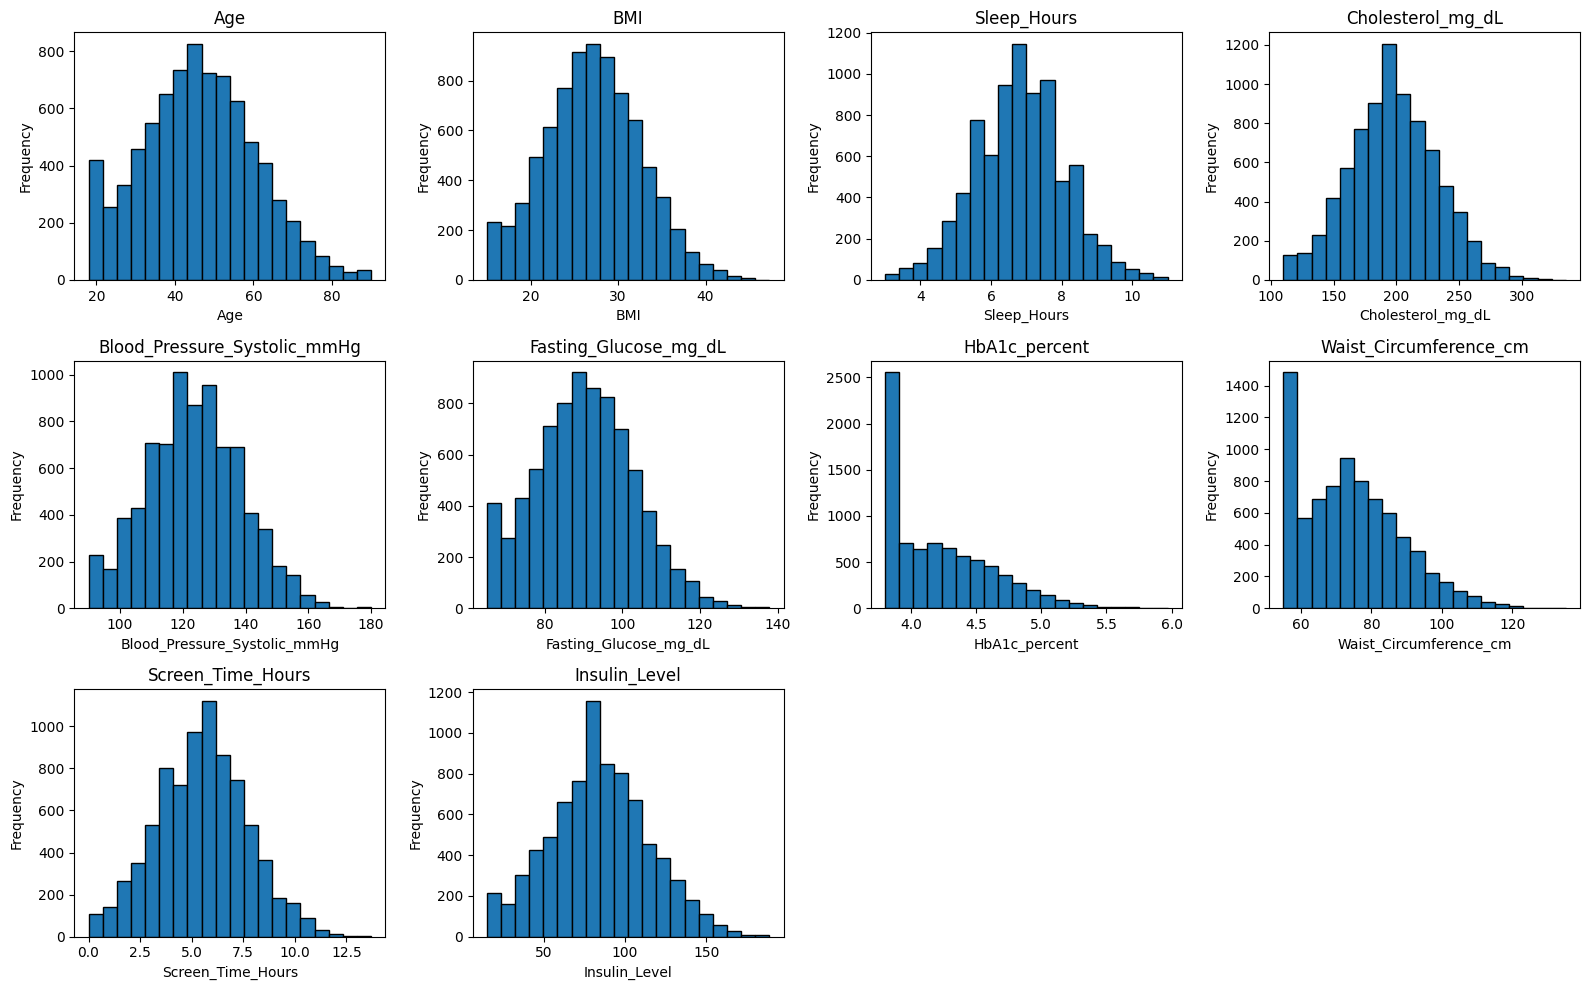

In [ ]:
# List of numeric columns that we want to visualise
numeric_cols = ['Age', 'BMI', 'Sleep_Hours', 'Cholesterol_mg_dL',
                'Blood_Pressure_Systolic_mmHg', 'Fasting_Glucose_mg_dL',
                'HbA1c_percent', 'Waist_Circumference_cm',
                'Screen_Time_Hours', 'Insulin_Level']


# Create a figure with 3 rows and 4 columns of plots
# This gives us space for 12 plots
fig, axes = plt.subplots(3, 4, figsize=(16, 10))


# Convert the 3x4 axes structure into a simple 1-dimensional list
# This makes it easier to access each plot using axes[i]
axes = axes.flatten()


# Loop through each numeric column
for i, col in enumerate(numeric_cols):

    # Create a histogram for the current column
    # bins=20 divides the values into 20 groups
    # edgecolor adds a border around each bar
    axes[i].hist(data[col], bins=20, edgecolor='black')

    # Add the column name as the title of the plot
    axes[i].set_title(col)

    # Label the x-axis with the column name
    axes[i].set_xlabel(col)

    # The y-axis shows how many values fall into each range
    axes[i].set_ylabel('Frequency')


# We created space for 12 plots, but we only have 10 variables
# Remove the extra empty plots
for i in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[i])


# Adjust the spacing so that titles and labels do not overlap
plt.tight_layout()


# Display all the plots
plt.show()

## Interpretation: Distribution of Numerical Variables:

The histograms illustrate the distributions of ten numerical variables in the diabetes risk dataset. They help us understand the **central tendency, spread, skewness and potential unusual values** in the data.

### 1. Interpretation of Individual Variables

**Age**
- Approximately bell-shaped distribution.
- Most patients are aged between 30 and 60 years, with the highest concentration around 40–50 years.

**Body Mass Index (BMI)**
- Roughly bell-shaped distribution with a slight right skew.
- Most BMI values range between 20 and 35, with the highest concentration around 25–30.

**Sleep Hours**
- Approximately bell-shaped distribution.
- Most patients report 5–8 hours of sleep, with fewer observations at very low or high durations.

**Cholesterol (mg/dL)**
- Approximately bell-shaped distribution, centred around 190–210 mg/dL.
- Most observations fall between approximately 150 and 250 mg/dL.

**Systolic Blood Pressure (mmHg)**
- Roughly bell-shaped distribution.
- Most readings are between 110 and 140 mmHg, with the highest concentration around 120–130 mmHg.

**Fasting Glucose (mg/dL)**
- Approximately bell-shaped distribution, centred around 90 mg/dL.
- Most values range between approximately 75 and 110 mg/dL.

**HbA1c (%)**
- Noticeably right-skewed distribution.
- A large concentration of values occurs near 3.8%, followed by decreasing frequencies at higher values.
- This unusual concentration near the lower boundary requires further investigation.

**Waist Circumference (cm)**
- Right-skewed distribution.
- Most values are between approximately 60 and 90 cm.
- A noticeable concentration near 55 cm may indicate a potential data-quality issue that needs further investigation.

**Screen Time (Hours)**
- Approximately bell-shaped distribution.
- Most patients report 3–8 hours of screen time, with the highest concentration around 5–6 hours.

**Insulin Level**
- Roughly bell-shaped distribution with a slight right skew.
- Most observations fall between approximately 50 and 120, with fewer observations at higher insulin levels.

### 2. Overall Inference

Most numerical variables, including Age, BMI, Sleep_Hours, Cholesterol and Fasting_Glucose, have approximately bell-shaped distributions.

However, **HbA1c and Waist_Circumference show unusual patterns**, particularly large concentrations of values near their lower boundaries.

These findings demonstrate why examining numerical distributions is an important part of Exploratory Data Analysis (EDA).

## Stage 6 — Bivariate analysis | PRAC1 Task 2c
Bivariate analysis compares **two variables**. We begin with categorical vs outcome, then numerical vs outcome, followed by numerical vs numerical. Original chart alternatives are retained so students can see which comparison is communicated most clearly.

**Careful:** A raw count and a within-group percentage answer different questions; group sizes can differ. A group difference does not prove causation.

**Analysis plan:** Start with categorical-vs-outcome comparisons (RQ1 and RQ2), continue with numerical-vs-outcome comparisons (RQ1 and RQ3), and then numerical relationships (RQ4).

### 6A. Categorical variables compared with diabetes-risk outcome
The following examples include stacked counts, grouped charts, within-category percentages, crosstabs and Pandas plotting. Each was retained to demonstrate different presentations of related questions.

## Categorical Variables by Diabetes Risk

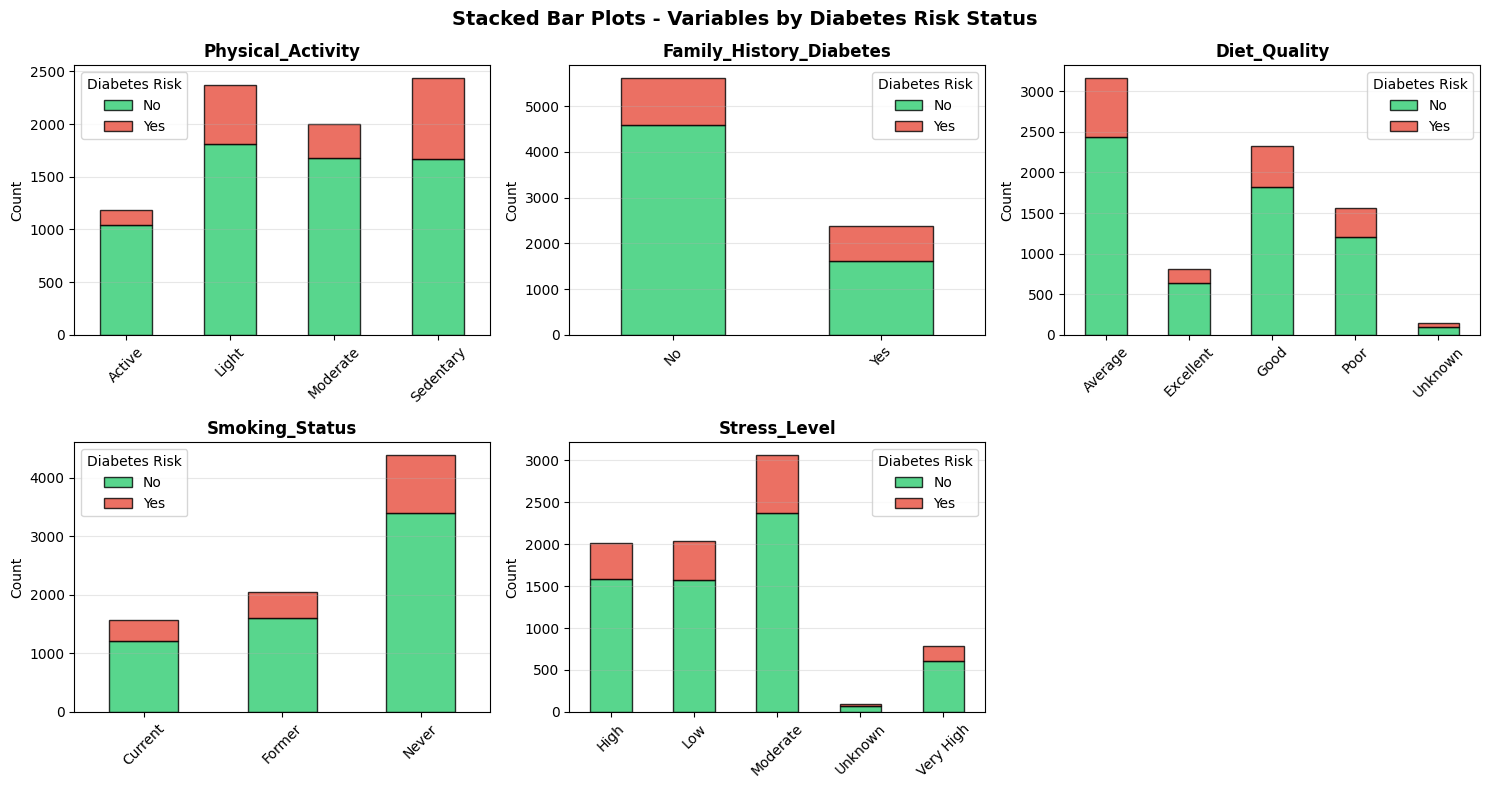

In [ ]:
# Stacked bar plots showing composition by diabetes risk
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Stacked Bar Plots - Variables by Diabetes Risk Status', fontsize=14, fontweight='bold')
axes = axes.flatten()

categorical_cols = ['Physical_Activity', 'Family_History_Diabetes', 'Diet_Quality',
                   'Smoking_Status', 'Stress_Level']

for idx, col in enumerate(categorical_cols):
    # Create cross-tabulation
    crosstab = pd.crosstab(data[col], data['Diabetes_Risk'])

    # Create stacked bar plot
    crosstab.plot(kind='bar', stacked=True, ax=axes[idx],
                 color=['#2ecc71', '#e74c3c'], alpha=0.8, edgecolor='black')
    axes[idx].set_title(col, fontweight='bold')
    axes[idx].set_ylabel('Count')
    axes[idx].set_xlabel('')
    axes[idx].legend(title='Diabetes Risk', labels=['No', 'Yes'])
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].grid(alpha=0.3, axis='y')

# Remove extra subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

**Count vs percentage:** Grouped and stacked count charts show the number of observations, but categories contain different numbers of patients. To compare risk prevalence fairly for RQ1/RQ2, use **row percentages** (each category totals 100%) in the later crosstabs.

### Interpretation: Lifestyle Factors, Family History and Diabetes Risk

The stacked bar charts compare the number of patients classified as having diabetes risk (`Yes`) and not having diabetes risk (`No`) across five categorical variables.

**Key Findings:**

- **Physical Activity:** Sedentary patients have the highest number of diabetes-risk cases, while active patients have the lowest.
- **Family History:** Patients with a family history of diabetes appear to have a higher proportion of diabetes-risk cases.
- **Diet Quality:** The Average diet category contains the most patients, with relatively small differences in risk proportions across categories.
- **Smoking Status:** Never-smokers represent the largest group, but diabetes-risk proportions appear broadly similar across smoking categories.
- **Stress Level:** Moderate stress is the most common category, with no clear pattern in diabetes-risk proportions.

### Overall Inference and Connection to RQ2

The findings suggest that **physical activity and family history show clearer associations with diabetes risk classification** than diet quality, smoking status and stress level.

However, these charts display counts rather than percentages. Further percentage-based comparisons are needed to assess differences between groups more accurately.

**RQ2:** *How are lifestyle factors and family history associated with diabetes risk?*

The results provide preliminary evidence of associations, particularly for physical activity and family history, but do not establish causation.

## PERCENTAGE STACKED PLOTS - Risk Distribution

In [ ]:
import pandas as pd
import plotly.express as px

# Step 1: Select categorical variables
categorical_cols = [
    'Physical_Activity',
    'Family_History_Diabetes',
    'Diet_Quality',
    'Smoking_Status',
    'Stress_Level'
]

# Step 2: Create a chart for each variable
for col in categorical_cols:

    # Calculate the percentage of Yes and No within each category
    risk = pd.crosstab(
        data[col],
        data['Diabetes_Risk'],
        normalize='index'
    ) * 100

    # Convert the category names from the index into a normal column
    # This allows Plotly to use the categories on the x-axis
    risk = risk.reset_index()

    # Step 3: Create the stacked bar chart
    fig = px.bar(
        risk,
        x=col,                            # Categorical variable on x-axis
        y=['No', 'Yes'],                  # Diabetes risk percentages
        title=col.replace('_', ' '),      # Chart title
        barmode='stack',                 # Stack No and Yes percentages
        labels={
            'value': 'Percentage (%)',
            'variable': 'Diabetes Risk'
        },
        color_discrete_map={
            'No': '#2ecc71',             # Green
            'Yes': '#e74c3c'             # Red
        }
    )

    # Set the y-axis between 0 and 100%
    fig.update_yaxes(range=[0, 100])

    # Display the chart
    fig.show()

### Interpretation — Percentage-stacked categories (RQ2)

The bars each total **100% within the category**. The clearest contrasts are **Sedentary 31.40% vs Active 12.62% `Yes`**, and **Family History Yes 32.52% vs No 18.13% `Yes`**. Diet-quality groups with known values are fairly close (**20.42%–22.91%**); smoking (**21.77%–23.06%**) and known stress categories (**21.67%–23.04%**) also show small unadjusted differences. **RQ2:** Physical activity and family history show clearer descriptive variation here; these are not adjusted causal effects.


## Categorical variables compared with Diabetes Risk

A cross-tabulation counts combinations of categories. Using `normalize="index"` converts each row into proportions, making groups easier to compare.


### Physical Activity and Diabetes Risk

In [ ]:

# Percentage within each category
comparison = pd.crosstab(
    data["Physical_Activity"],
    data["Diabetes_Risk"],
    normalize="index"
) * 100

comparison.round(1)


Diabetes_Risk,No,Yes
Physical_Activity,,
Active,87.4,12.6
Light,76.5,23.5
Moderate,84.0,16.0
Sedentary,68.6,31.4


**RQ2 — physical activity (cleaned data):** `Diabetes_Risk = Yes` occurs in **31.40% of sedentary**, **23.55% of light**, **15.99% of moderate**, and **12.62% of active** patients. The sedentary–active difference is **18.78 percentage points**. This is an observed association, not evidence that activity alone causes the outcome.

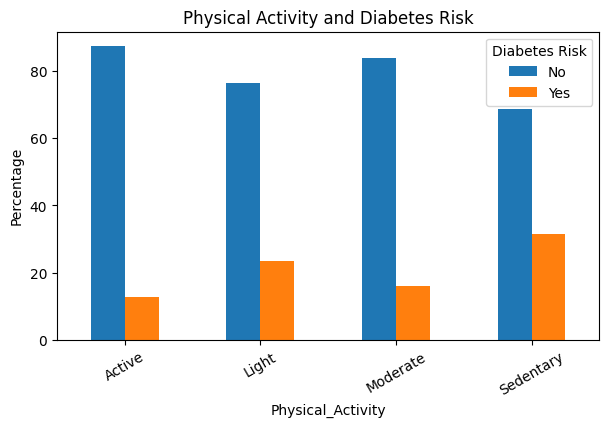

In [ ]:

comparison.plot(kind="bar", figsize=(7, 4))
plt.title("Physical Activity and Diabetes Risk")
plt.ylabel("Percentage")
plt.xticks(rotation=30)
plt.legend(title="Diabetes Risk")
plt.show()


**Chart interpretation (RQ2):** The physical-activity grouped percentage chart repeats the within-category proportions. **Sedentary 31.40%** is highest and **Active 12.62%** lowest for `Yes`. Do not confuse percentage differences with differences in group sizes.

### Family History and Diabetes Risk

In [ ]:

# Percentage within each category
comparison = pd.crosstab(
    data["Family_History_Diabetes"],
    data["Diabetes_Risk"],
    normalize="index"
) * 100

comparison.round(1)


Diabetes_Risk,No,Yes
Family_History_Diabetes,,
No,81.9,18.1
Yes,67.5,32.5


**Interpretation — Family history (RQ2):** **32.52%** of those reporting a family history are labelled `Yes`, compared with **18.13%** of those reporting none (a difference of **14.39 percentage points**). Family history shows a clear descriptive association with the dataset's risk classification; causal or clinical conclusions are not justified.

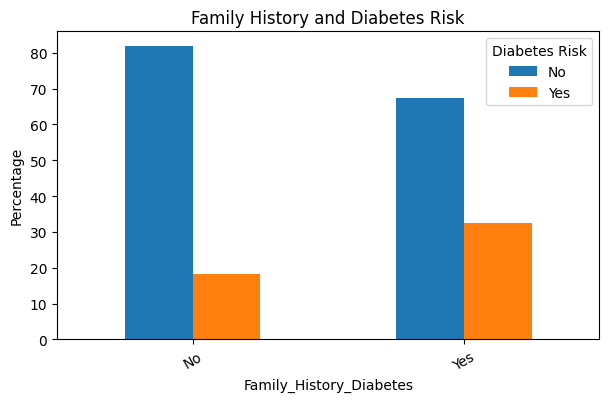

In [ ]:

comparison.plot(kind="bar", figsize=(7, 4))
plt.title("Family History and Diabetes Risk")
plt.ylabel("Percentage")
plt.xticks(rotation=30)
plt.legend(title="Diabetes Risk")
plt.show()


**Chart interpretation (RQ2):** Reported family history is associated with a higher `Yes` percentage (**32.52%**) than no history (**18.13%**); this is descriptive rather than causal.

### Diet Quality and Diabetes Risk

In [ ]:

# Percentage within each category
comparison = pd.crosstab(
    data["Diet_Quality"],
    data["Diabetes_Risk"],
    normalize="index"
) * 100

comparison.round(1)


Diabetes_Risk,No,Yes
Diet_Quality,,
Average,77.1,22.9
Excellent,79.6,20.4
Good,78.1,21.9
Poor,77.3,22.7
Unknown,70.8,29.2


**Interpretation — Diet quality (RQ2):** `Yes` percentages are **22.91% Average**, **20.42% Excellent**, **21.89% Good**, **22.66% Poor**, and **29.17% Unknown**. The known diet categories differ only modestly, with no clear consistent order. `Unknown` represents missing diet information, not a diet quality level.

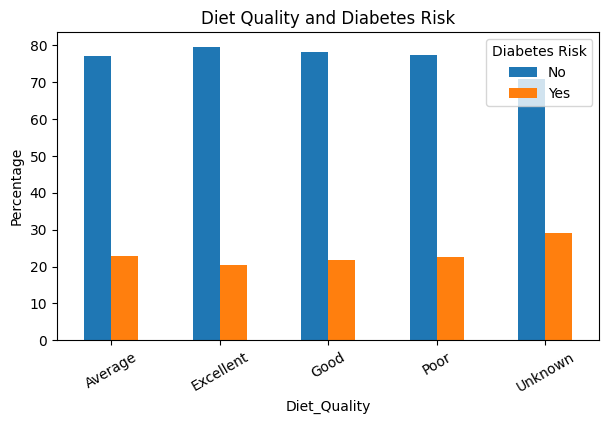

In [ ]:

comparison.plot(kind="bar", figsize=(7, 4))
plt.title("Diet Quality and Diabetes Risk")
plt.ylabel("Percentage")
plt.xticks(rotation=30)
plt.legend(title="Diabetes Risk")
plt.show()


**Chart interpretation (RQ2):** Known diet groups have similar `Yes` percentages (**20.42%–22.91%**); `Unknown` (**29.17%**) indicates unreported diet quality and should not be treated as a nutritional level.

### Smoking Status and Diabetes Risk

In [ ]:

# Percentage within each category
comparison = pd.crosstab(
    data["Smoking_Status"],
    data["Diabetes_Risk"],
    normalize="index"
) * 100

comparison.round(1)


Diabetes_Risk,No,Yes
Smoking_Status,,
Current,76.9,23.1
Former,78.2,21.8
Never,77.5,22.5


**RQ2 — smoking status (cleaned data):** `Yes` percentages are **23.06% Current**, **21.77% Former**, and **22.51% Never**. Differences are small in this dataset; visual differences alone do not establish an important effect.

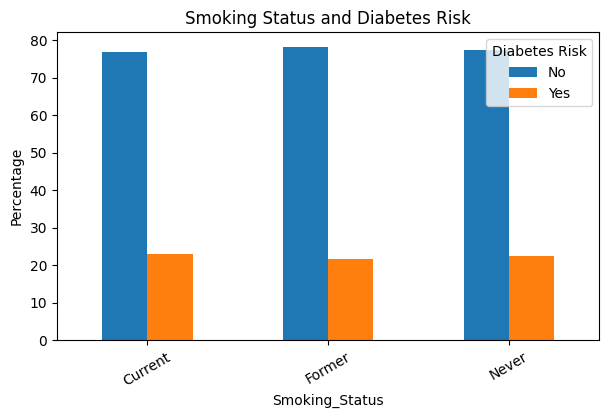

In [ ]:

comparison.plot(kind="bar", figsize=(7, 4))
plt.title("Smoking Status and Diabetes Risk")
plt.ylabel("Percentage")
plt.xticks(rotation=30)
plt.legend(title="Diabetes Risk")
plt.show()


**Chart interpretation (RQ2):** `Yes` percentages by smoking status are **23.06% Current**, **21.77% Former**, **22.51% Never**. These small group differences are not evidence that smoking has no effect on health.

### Stress Level and Diabetes Risk

In [ ]:

# Percentage within each category
comparison = pd.crosstab(
    data["Stress_Level"],
    data["Diabetes_Risk"],
    normalize="index"
) * 100

comparison.round(1)


Diabetes_Risk,No,Yes
Stress_Level,,
High,78.3,21.7
Low,77.0,23.0
Moderate,77.5,22.5
Unknown,78.1,21.9
Very High,77.4,22.6


**RQ2 — stress level (cleaned data):** The `Yes` percentages across reported stress levels range from **21.67% (High)** to **23.04% (Low)**. The range is small and should not be interpreted as a causal stress effect. `Unknown` represents missing responses.

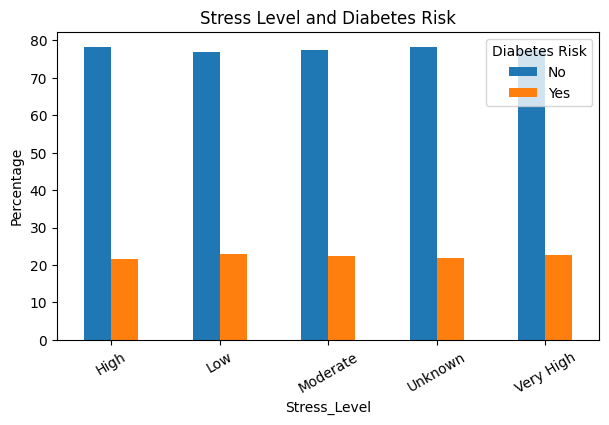

In [ ]:

comparison.plot(kind="bar", figsize=(7, 4))
plt.title("Stress Level and Diabetes Risk")
plt.ylabel("Percentage")
plt.xticks(rotation=30)
plt.legend(title="Diabetes Risk")
plt.show()


**Chart interpretation (RQ2):** Across recorded stress groups, `Yes` varies narrowly (**21.67%–23.04%**); there is no clear gradient in these unadjusted data.

### Gender and Diabetes Risk

In [ ]:

# Percentage within each category
comparison = pd.crosstab(
    data["Gender"],
    data["Diabetes_Risk"],
    normalize="index"
) * 100

comparison.round(1)


Diabetes_Risk,No,Yes
Gender,,
Female,77.0,23.0
Male,78.1,21.9


**RQ1 — gender (cleaned data):** After standardisation, `Yes` occurs in **22.96% of female** and **21.86% of male** records—a difference of **1.10 percentage points**. The unadjusted gender difference is much smaller than the age-group and physical-activity patterns.

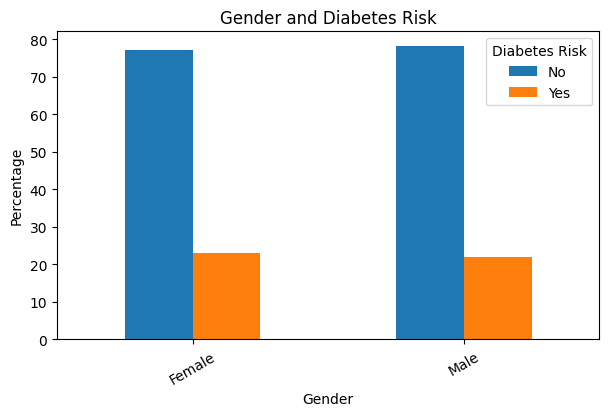

In [ ]:

comparison.plot(kind="bar", figsize=(7, 4))
plt.title("Gender and Diabetes Risk")
plt.ylabel("Percentage")
plt.xticks(rotation=30)
plt.legend(title="Diabetes Risk")
plt.show()


### 6B. Numerical variables compared with diabetes-risk outcome
Compare group distributions and averages. Box plots show median and spread; mean plots and mean ± SD add different summaries. Density histograms make the shapes easier to compare when group sizes differ.

## Numeric Variables by Risk Status

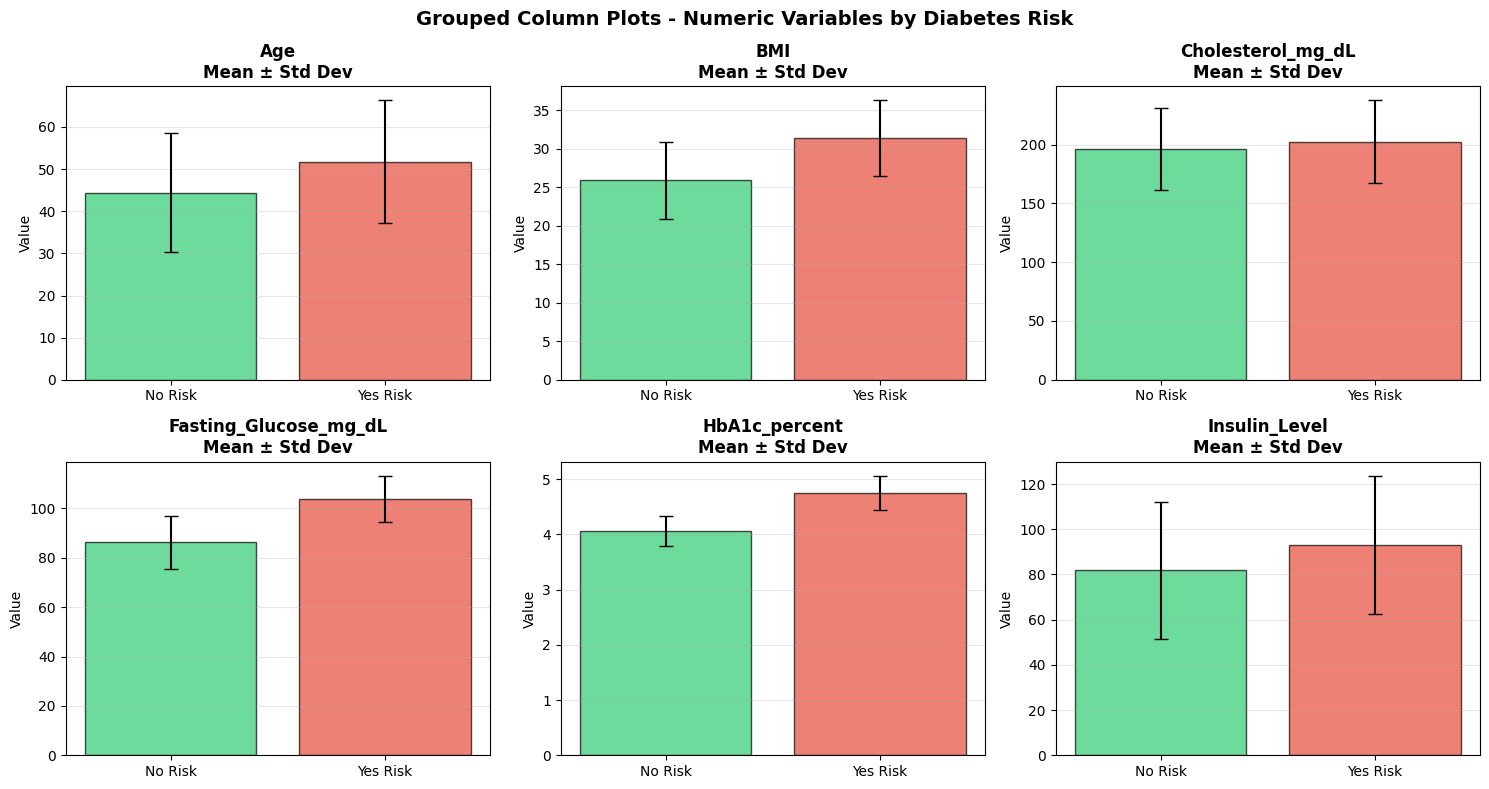

In [ ]:
# Grouped bar plots comparing numeric variables by diabetes risk
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Grouped Column Plots - Numeric Variables by Diabetes Risk', fontsize=14, fontweight='bold')
axes = axes.flatten()

key_numeric = ['Age', 'BMI', 'Cholesterol_mg_dL', 'Fasting_Glucose_mg_dL', 'HbA1c_percent', 'Insulin_Level']

for idx, col in enumerate(key_numeric):
    # Create box plot (grouped view)
    data_no_risk = data[data['Diabetes_Risk'] == 'No'][col].dropna()
    data_yes_risk = data[data['Diabetes_Risk'] == 'Yes'][col].dropna()

    # Create grouped bar showing means
    means = [data_no_risk.mean(), data_yes_risk.mean()]
    stds = [data_no_risk.std(), data_yes_risk.std()]

    x_pos = np.arange(2)
    axes[idx].bar(x_pos, means, yerr=stds, capsize=5,
                 color=['#2ecc71', '#e74c3c'], alpha=0.7, edgecolor='black')
    axes[idx].set_xticks(x_pos)
    axes[idx].set_xticklabels(['No Risk', 'Yes Risk'])
    axes[idx].set_title(f'{col}\nMean ± Std Dev', fontweight='bold')
    axes[idx].set_ylabel('Value')
    axes[idx].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Interpretation — Grouped numerical means (RQ1/RQ3)

The `Yes` group has higher mean **Age (51.78 vs 44.39)**, **BMI (31.39 vs 25.90)**, **Waist Circumference (84.45 vs 71.18 cm)**, **Fasting Glucose (103.86 vs 86.33 mg/dL)** and **HbA1c (4.75% vs 4.06%)**. These differences help address **RQ1 and RQ3**, but means can hide group overlap, skewness and unusual values; check the box plots next.

**Interpretation — Numerical averages by risk group (RQ1 and RQ3):** The `Yes` group has higher mean **Age (51.78 vs 44.39 years)**, **BMI (31.39 vs 25.90)**, **Waist Circumference (84.45 vs 71.18 cm)**, **Insulin (93.14 vs 81.78)**, **Fasting Glucose (103.86 vs 86.33 mg/dL)** and **HbA1c (4.75% vs 4.06%)**. The difference in mean **Sleep Hours (6.80 vs 6.78)** is negligible. Group means are summaries; distributions overlap and these comparisons are not adjusted for other variables.


## Box plots — checking spread and possible outliers

Box plots help us compare the centre, spread and possible unusual values in numerical variables.


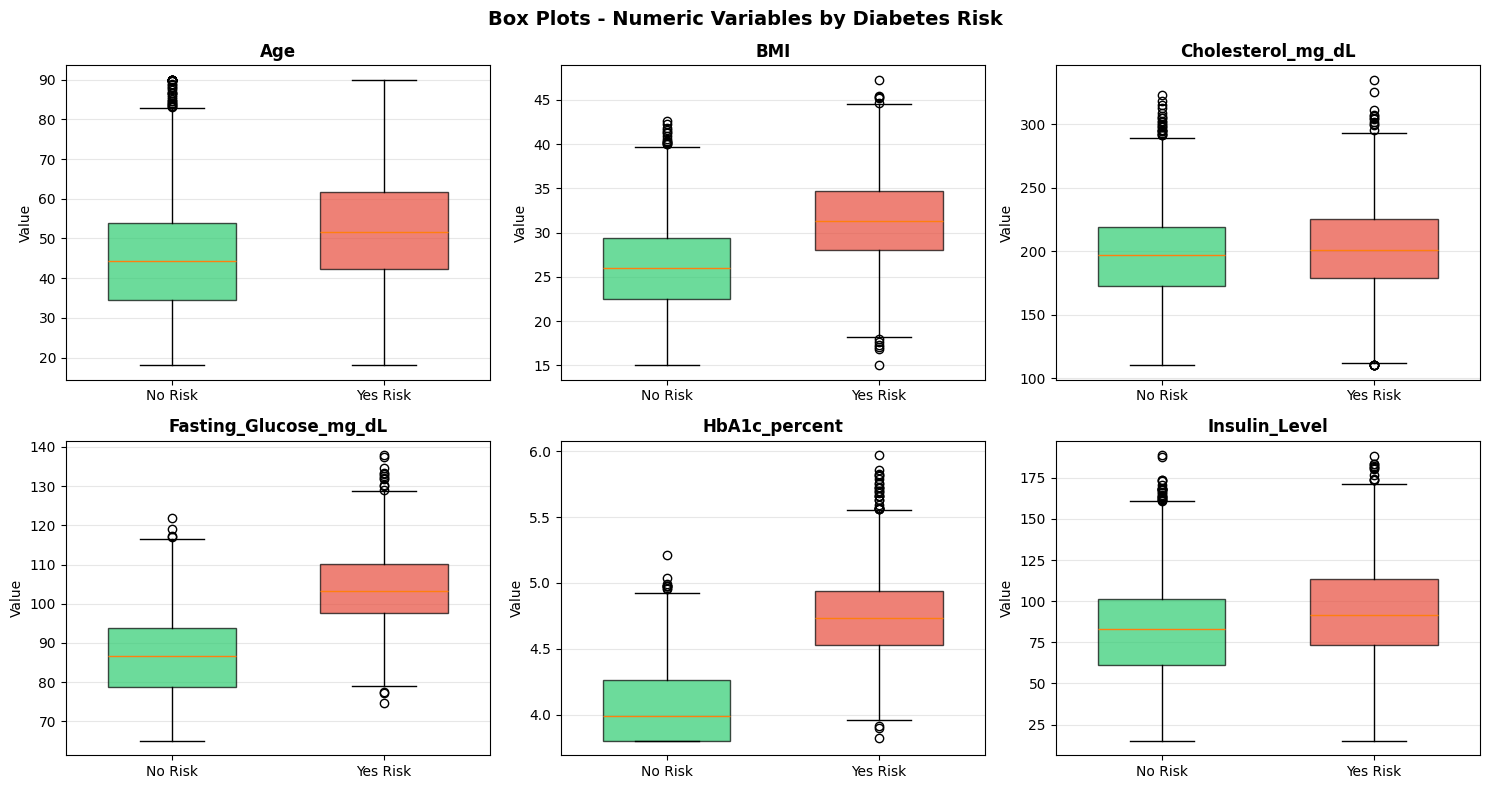

In [ ]:
# Box plots for easy comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Box Plots - Numeric Variables by Diabetes Risk', fontsize=14, fontweight='bold')
axes = axes.flatten()

key_vars = ['Age', 'BMI', 'Cholesterol_mg_dL', 'Fasting_Glucose_mg_dL', 'HbA1c_percent', 'Insulin_Level']

for idx, var in enumerate(key_vars):
    # Create box plot
    bp = axes[idx].boxplot([data[data['Diabetes_Risk'] == 'No'][var].dropna(),
                            data[data['Diabetes_Risk'] == 'Yes'][var].dropna()],
                           tick_labels=['No Risk', 'Yes Risk'],
                           patch_artist=True,
                           widths=0.6)

    # Color the boxes
    colors = ['#2ecc71', '#e74c3c']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    axes[idx].set_title(var, fontweight='bold')
    axes[idx].set_ylabel('Value')
    axes[idx].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Interpretation — Box plots by diabetes-risk label (RQ3)

Use the medians, spread and overlap to supplement the averages. The `Yes` group generally has higher BMI, waist circumference and glucose-related measurements, but observations from `No` and `Yes` overlap. Points outside whiskers are **potential** outliers under a plotting rule, not necessarily errors. **RQ3:** Differences are descriptive; no clinical diagnosis or causal inference follows from the box plots.


## Numerical variables compared with Diabetes Risk

Here we use box plots to compare the distribution of important numerical variables between people with `Diabetes_Risk = Yes` and `Diabetes_Risk = No`.


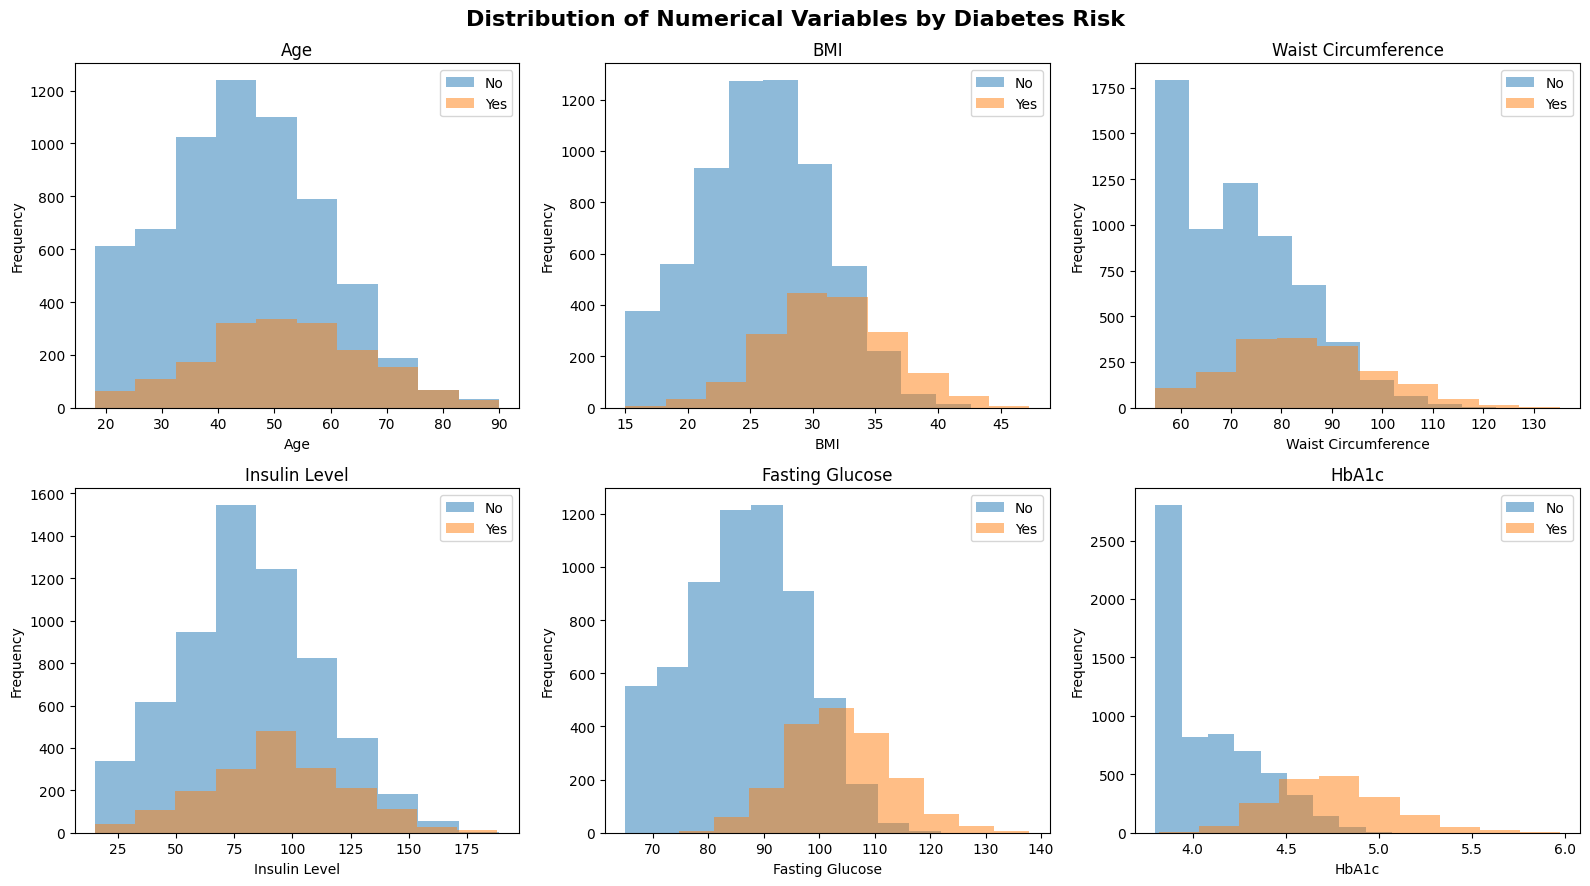

In [ ]:
# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

fig.suptitle(
    "Distribution of Numerical Variables by Diabetes Risk",
    fontsize=16,
    fontweight="bold"
)

# Age
axes[0,0].hist(
    data[data["Diabetes_Risk"] == "No"]["Age"],
    alpha=0.5,
    label="No"
)

axes[0,0].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Age"],
    alpha=0.5,
    label="Yes"
)

axes[0,0].set_title("Age")
axes[0,0].set_xlabel("Age")
axes[0,0].set_ylabel("Frequency")
axes[0,0].legend()


# BMI
axes[0,1].hist(
    data[data["Diabetes_Risk"] == "No"]["BMI"],
    alpha=0.5,
    label="No"
)

axes[0,1].hist(
    data[data["Diabetes_Risk"] == "Yes"]["BMI"],
    alpha=0.5,
    label="Yes"
)

axes[0,1].set_title("BMI")
axes[0,1].set_xlabel("BMI")
axes[0,1].set_ylabel("Frequency")
axes[0,1].legend()


# Waist Circumference
axes[0,2].hist(
    data[data["Diabetes_Risk"] == "No"]["Waist_Circumference_cm"],
    alpha=0.5,
    label="No"
)

axes[0,2].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Waist_Circumference_cm"],
    alpha=0.5,
    label="Yes"
)

axes[0,2].set_title("Waist Circumference")
axes[0,2].set_xlabel("Waist Circumference")
axes[0,2].set_ylabel("Frequency")
axes[0,2].legend()


# Insulin Level
axes[1,0].hist(
    data[data["Diabetes_Risk"] == "No"]["Insulin_Level"],
    alpha=0.5,
    label="No"
)

axes[1,0].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Insulin_Level"],
    alpha=0.5,
    label="Yes"
)

axes[1,0].set_title("Insulin Level")
axes[1,0].set_xlabel("Insulin Level")
axes[1,0].set_ylabel("Frequency")
axes[1,0].legend()


# Fasting Glucose
axes[1,1].hist(
    data[data["Diabetes_Risk"] == "No"]["Fasting_Glucose_mg_dL"],
    alpha=0.5,
    label="No"
)

axes[1,1].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Fasting_Glucose_mg_dL"],
    alpha=0.5,
    label="Yes"
)

axes[1,1].set_title("Fasting Glucose")
axes[1,1].set_xlabel("Fasting Glucose")
axes[1,1].set_ylabel("Frequency")
axes[1,1].legend()


# HbA1c
axes[1,2].hist(
    data[data["Diabetes_Risk"] == "No"]["HbA1c_percent"],
    alpha=0.5,
    label="No"
)

axes[1,2].hist(
    data[data["Diabetes_Risk"] == "Yes"]["HbA1c_percent"],
    alpha=0.5,
    label="Yes"
)

axes[1,2].set_title("HbA1c")
axes[1,2].set_xlabel("HbA1c")
axes[1,2].set_ylabel("Frequency")
axes[1,2].legend()

plt.tight_layout()
plt.show()

### Interpretation — Overlaid count histograms (RQ1/RQ3)

The `Yes` distribution is generally shifted towards **older ages, higher BMI, greater waist circumference, higher fasting glucose and higher HbA1c** compared with `No`. However, the two groups have unequal sizes (**1,794 Yes; 6,206 No**), so raw histogram *heights* should not be used to compare prevalence or relative distribution shapes directly. The density-normalised charts below are better for comparing shapes.

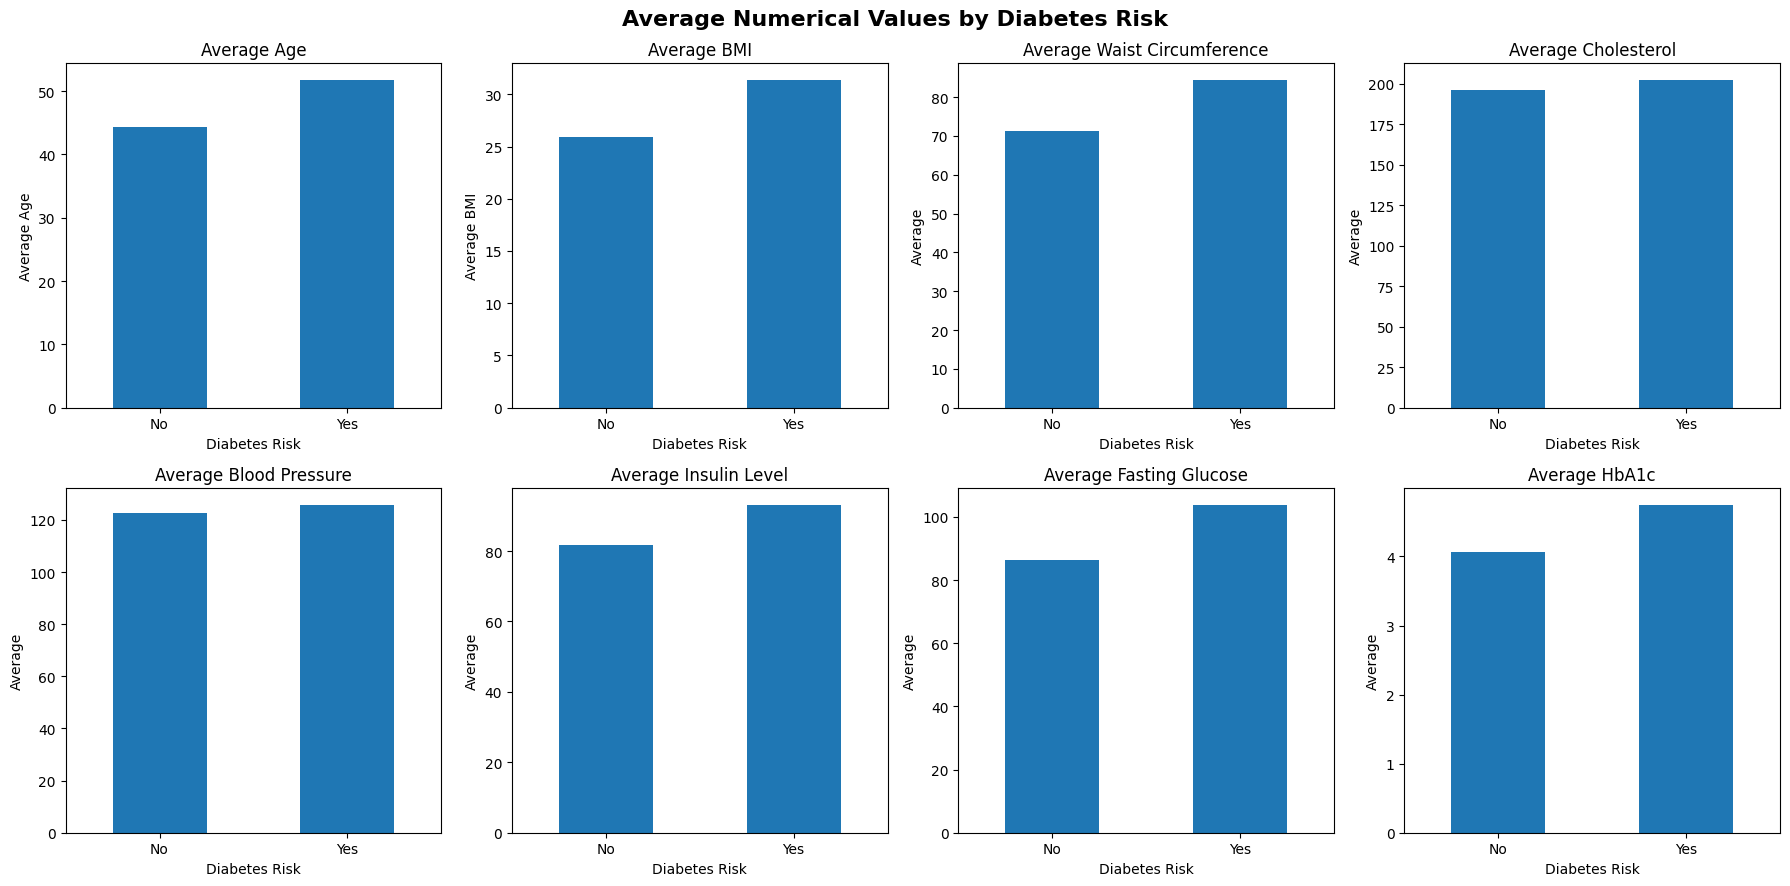

In [ ]:
# Create subplots
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

fig.suptitle(
    "Average Numerical Values by Diabetes Risk",
    fontsize=16,
    fontweight="bold"
)

# Age
data.groupby("Diabetes_Risk")["Age"].mean().plot(
    kind="bar",
    ax=axes[0,0]
)

axes[0,0].set_title("Average Age")
axes[0,0].set_xlabel("Diabetes Risk")
axes[0,0].set_ylabel("Average Age")
axes[0,0].tick_params(axis="x", rotation=0)


# BMI
data.groupby("Diabetes_Risk")["BMI"].mean().plot(
    kind="bar",
    ax=axes[0,1]
)

axes[0,1].set_title("Average BMI")
axes[0,1].set_xlabel("Diabetes Risk")
axes[0,1].set_ylabel("Average BMI")
axes[0,1].tick_params(axis="x", rotation=0)


# Waist Circumference
data.groupby("Diabetes_Risk")["Waist_Circumference_cm"].mean().plot(
    kind="bar",
    ax=axes[0,2]
)

axes[0,2].set_title("Average Waist Circumference")
axes[0,2].set_xlabel("Diabetes Risk")
axes[0,2].set_ylabel("Average")
axes[0,2].tick_params(axis="x", rotation=0)


# Cholesterol
data.groupby("Diabetes_Risk")["Cholesterol_mg_dL"].mean().plot(
    kind="bar",
    ax=axes[0,3]
)

axes[0,3].set_title("Average Cholesterol")
axes[0,3].set_xlabel("Diabetes Risk")
axes[0,3].set_ylabel("Average")
axes[0,3].tick_params(axis="x", rotation=0)


# Blood Pressure
data.groupby("Diabetes_Risk")["Blood_Pressure_Systolic_mmHg"].mean().plot(
    kind="bar",
    ax=axes[1,0]
)

axes[1,0].set_title("Average Blood Pressure")
axes[1,0].set_xlabel("Diabetes Risk")
axes[1,0].set_ylabel("Average")
axes[1,0].tick_params(axis="x", rotation=0)


# Insulin
data.groupby("Diabetes_Risk")["Insulin_Level"].mean().plot(
    kind="bar",
    ax=axes[1,1]
)

axes[1,1].set_title("Average Insulin Level")
axes[1,1].set_xlabel("Diabetes Risk")
axes[1,1].set_ylabel("Average")
axes[1,1].tick_params(axis="x", rotation=0)


# Fasting Glucose
data.groupby("Diabetes_Risk")["Fasting_Glucose_mg_dL"].mean().plot(
    kind="bar",
    ax=axes[1,2]
)

axes[1,2].set_title("Average Fasting Glucose")
axes[1,2].set_xlabel("Diabetes Risk")
axes[1,2].set_ylabel("Average")
axes[1,2].tick_params(axis="x", rotation=0)


# HbA1c
data.groupby("Diabetes_Risk")["HbA1c_percent"].mean().plot(
    kind="bar",
    ax=axes[1,3]
)

axes[1,3].set_title("Average HbA1c")
axes[1,3].set_xlabel("Diabetes Risk")
axes[1,3].set_ylabel("Average")
axes[1,3].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Interpretation — All eight mean comparisons (RQ1/RQ3)

The largest contrasts in these displayed averages are in **fasting glucose (103.86 vs 86.33 mg/dL)**, **waist circumference (84.45 vs 71.18 cm)** and **BMI (31.39 vs 25.90)**, with higher values in the `Yes` group. **Cholesterol (202.47 vs 196.19 mg/dL)** and **systolic blood pressure (125.82 vs 122.71 mmHg)** differ less. **RQ1/RQ3:** Interpret magnitudes in their own units; unlike a standardised effect size, numerical differences in different units cannot be ranked directly for importance.

**Interpretation of group summaries:** A higher average does not mean every member of the `Yes` group has a higher reading. Compare distributions as well as means. No individual-level diagnosis should be drawn from the `Diabetes_Risk` flag.

### **Density histograms for numerical variables**

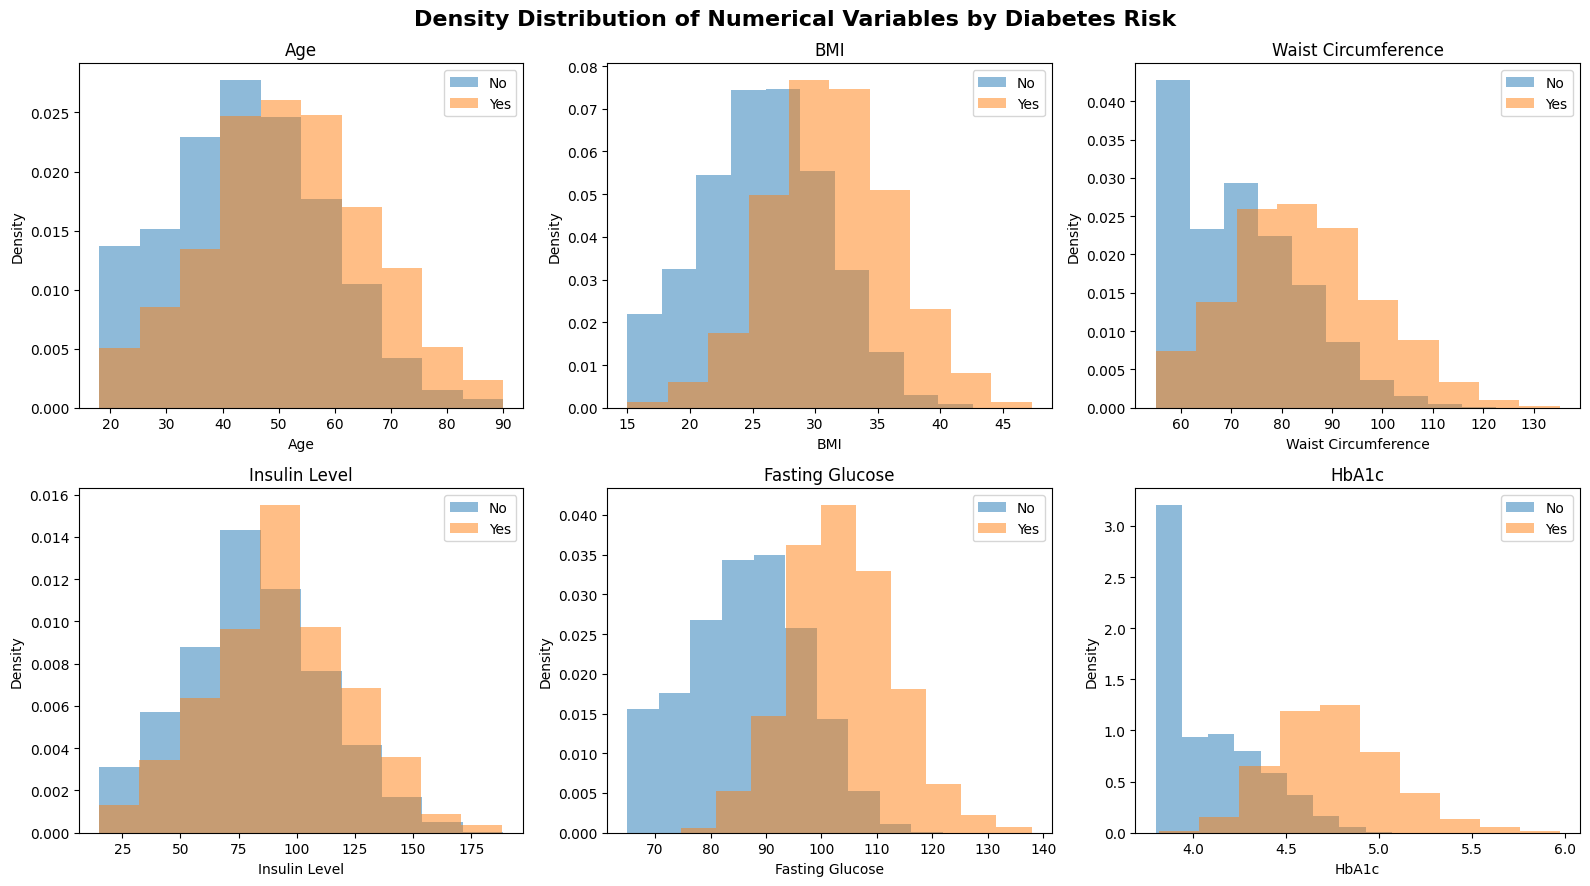

In [ ]:
# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

fig.suptitle(
    "Density Distribution of Numerical Variables by Diabetes Risk",
    fontsize=16,
    fontweight="bold"
)


# Age
axes[0,0].hist(
    data[data["Diabetes_Risk"] == "No"]["Age"],
    alpha=0.5,
    label="No",
    density=True
)

axes[0,0].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Age"],
    alpha=0.5,
    label="Yes",
    density=True
)

axes[0,0].set_title("Age")
axes[0,0].set_xlabel("Age")
axes[0,0].set_ylabel("Density")
axes[0,0].legend()


# BMI
axes[0,1].hist(
    data[data["Diabetes_Risk"] == "No"]["BMI"],
    alpha=0.5,
    label="No",
    density=True
)

axes[0,1].hist(
    data[data["Diabetes_Risk"] == "Yes"]["BMI"],
    alpha=0.5,
    label="Yes",
    density=True
)

axes[0,1].set_title("BMI")
axes[0,1].set_xlabel("BMI")
axes[0,1].set_ylabel("Density")
axes[0,1].legend()


# Waist Circumference
axes[0,2].hist(
    data[data["Diabetes_Risk"] == "No"]["Waist_Circumference_cm"],
    alpha=0.5,
    label="No",
    density=True
)

axes[0,2].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Waist_Circumference_cm"],
    alpha=0.5,
    label="Yes",
    density=True
)

axes[0,2].set_title("Waist Circumference")
axes[0,2].set_xlabel("Waist Circumference")
axes[0,2].set_ylabel("Density")
axes[0,2].legend()


# Insulin Level
axes[1,0].hist(
    data[data["Diabetes_Risk"] == "No"]["Insulin_Level"],
    alpha=0.5,
    label="No",
    density=True
)

axes[1,0].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Insulin_Level"],
    alpha=0.5,
    label="Yes",
    density=True
)

axes[1,0].set_title("Insulin Level")
axes[1,0].set_xlabel("Insulin Level")
axes[1,0].set_ylabel("Density")
axes[1,0].legend()


# Fasting Glucose
axes[1,1].hist(
    data[data["Diabetes_Risk"] == "No"]["Fasting_Glucose_mg_dL"],
    alpha=0.5,
    label="No",
    density=True
)

axes[1,1].hist(
    data[data["Diabetes_Risk"] == "Yes"]["Fasting_Glucose_mg_dL"],
    alpha=0.5,
    label="Yes",
    density=True
)

axes[1,1].set_title("Fasting Glucose")
axes[1,1].set_xlabel("Fasting Glucose")
axes[1,1].set_ylabel("Density")
axes[1,1].legend()


# HbA1c
axes[1,2].hist(
    data[data["Diabetes_Risk"] == "No"]["HbA1c_percent"],
    alpha=0.5,
    label="No",
    density=True
)

axes[1,2].hist(
    data[data["Diabetes_Risk"] == "Yes"]["HbA1c_percent"],
    alpha=0.5,
    label="Yes",
    density=True
)

axes[1,2].set_title("HbA1c")
axes[1,2].set_xlabel("HbA1c")
axes[1,2].set_ylabel("Density")
axes[1,2].legend()


plt.tight_layout()
plt.show()

### Interpretation — Density histograms by risk group (RQ1/RQ3)

Unlike the preceding count histograms, `density=True` scales each group's histogram to total area 1, making the **distribution shapes** easier to compare despite unequal group sizes. The `Yes` group tends towards higher age, BMI, waist circumference, insulin, glucose and HbA1c values, although the distributions overlap. A higher density at a value is **not** the percentage of patients with `Diabetes_Risk = Yes` at that value.

### Mean numerical values by Diabetes Risk

In [ ]:

# Compare mean values for selected numerical variables
selected_variables = [
    "Age",
    "BMI",
    "Waist_Circumference_cm",
    "Cholesterol_mg_dL",
    "Blood_Pressure_Systolic_mmHg",
    "Insulin_Level",
    "Fasting_Glucose_mg_dL",
    "HbA1c_percent"
]

risk_means = data.groupby("Diabetes_Risk")[selected_variables].mean()
risk_means.round(2)


,Age,BMI,Waist_Circumference_cm,Cholesterol_mg_dL,Blood_Pressure_Systolic_mmHg,Insulin_Level,Fasting_Glucose_mg_dL,HbA1c_percent
Diabetes_Risk,,,,,,,,
No,44.39,25.90,71.18,196.19,122.71,81.78,86.33,4.06
Yes,51.78,31.39,84.45,202.47,125.82,93.14,103.86,4.75


**Interpretation of the printed mean table (RQ1/RQ3):** Use this table to check chart readings numerically. Examples: mean BMI **25.90 No** versus **31.39 Yes**, and fasting glucose **86.33 No** versus **103.86 Yes**. Differences in means are not sufficient to determine statistical significance or explain why the labels differ.

**RQ3 extension:** Numerical group summaries should support the box plots, not replace them. Look for overlap and possible extreme values when interpreting how far apart groups really are.

### 6C. Numerical vs numerical relationships
Use scatter plots and correlations to investigate how two numerical measurements vary together. Correlation is not causation. The heatmap is an overview, not a replacement for inspecting scatter plots.


## Relationships between numerical variables

Scatter plots are useful when both variables are numerical. They help us see whether two variables tend to increase or decrease together.


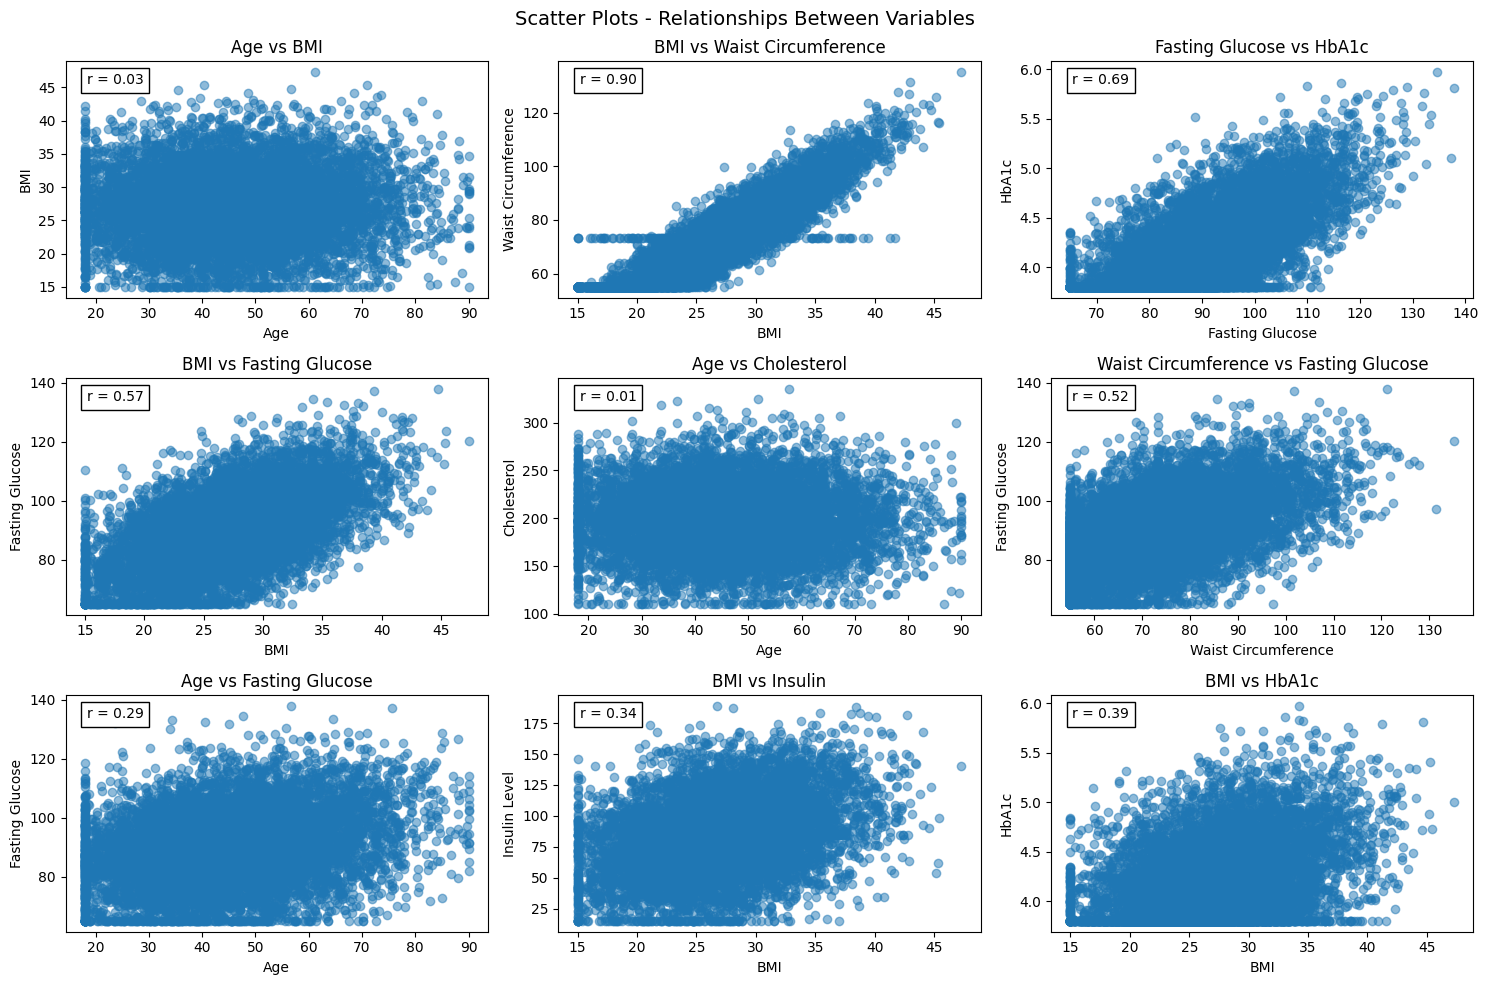

In [ ]:
# Create 3 x 3 subplots
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

fig.suptitle("Scatter Plots - Relationships Between Variables", fontsize=14)


# Plot 1: Age vs BMI
axes[0,0].scatter(data["Age"], data["BMI"], alpha=0.5)
axes[0,0].set_title("Age vs BMI")
axes[0,0].set_xlabel("Age")
axes[0,0].set_ylabel("BMI")

corr = data["Age"].corr(data["BMI"])

axes[0,0].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[0,0].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 2: BMI vs Waist Circumference
axes[0,1].scatter(data["BMI"], data["Waist_Circumference_cm"], alpha=0.5)
axes[0,1].set_title("BMI vs Waist Circumference")
axes[0,1].set_xlabel("BMI")
axes[0,1].set_ylabel("Waist Circumference")

corr = data["BMI"].corr(data["Waist_Circumference_cm"])

axes[0,1].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[0,1].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 3: Fasting Glucose vs HbA1c
axes[0,2].scatter(data["Fasting_Glucose_mg_dL"], data["HbA1c_percent"], alpha=0.5)
axes[0,2].set_title("Fasting Glucose vs HbA1c")
axes[0,2].set_xlabel("Fasting Glucose")
axes[0,2].set_ylabel("HbA1c")

corr = data["Fasting_Glucose_mg_dL"].corr(data["HbA1c_percent"])

axes[0,2].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[0,2].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 4: BMI vs Fasting Glucose
axes[1,0].scatter(data["BMI"], data["Fasting_Glucose_mg_dL"], alpha=0.5)
axes[1,0].set_title("BMI vs Fasting Glucose")
axes[1,0].set_xlabel("BMI")
axes[1,0].set_ylabel("Fasting Glucose")

corr = data["BMI"].corr(data["Fasting_Glucose_mg_dL"])

axes[1,0].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[1,0].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 5: Age vs Cholesterol
axes[1,1].scatter(data["Age"], data["Cholesterol_mg_dL"], alpha=0.5)
axes[1,1].set_title("Age vs Cholesterol")
axes[1,1].set_xlabel("Age")
axes[1,1].set_ylabel("Cholesterol")

corr = data["Age"].corr(data["Cholesterol_mg_dL"])

axes[1,1].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[1,1].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 6: Waist Circumference vs Fasting Glucose
axes[1,2].scatter(
    data["Waist_Circumference_cm"],
    data["Fasting_Glucose_mg_dL"],
    alpha=0.5
)

axes[1,2].set_title("Waist Circumference vs Fasting Glucose")
axes[1,2].set_xlabel("Waist Circumference")
axes[1,2].set_ylabel("Fasting Glucose")

corr = data["Waist_Circumference_cm"].corr(data["Fasting_Glucose_mg_dL"])

axes[1,2].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[1,2].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 7: Age vs Fasting Glucose
axes[2,0].scatter(data["Age"], data["Fasting_Glucose_mg_dL"], alpha=0.5)
axes[2,0].set_title("Age vs Fasting Glucose")
axes[2,0].set_xlabel("Age")
axes[2,0].set_ylabel("Fasting Glucose")

corr = data["Age"].corr(data["Fasting_Glucose_mg_dL"])

axes[2,0].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[2,0].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 8: BMI vs Insulin
axes[2,1].scatter(data["BMI"], data["Insulin_Level"], alpha=0.5)
axes[2,1].set_title("BMI vs Insulin")
axes[2,1].set_xlabel("BMI")
axes[2,1].set_ylabel("Insulin Level")

corr = data["BMI"].corr(data["Insulin_Level"])

axes[2,1].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[2,1].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


# Plot 9: BMI vs HbA1c
axes[2,2].scatter(data["BMI"], data["HbA1c_percent"], alpha=0.5)
axes[2,2].set_title("BMI vs HbA1c")
axes[2,2].set_xlabel("BMI")
axes[2,2].set_ylabel("HbA1c")

corr = data["BMI"].corr(data["HbA1c_percent"])

axes[2,2].text(
    0.05, 0.95,
    f"r = {corr:.2f}",
    transform=axes[2,2].transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white")
)


plt.tight_layout()
plt.show()

### Interpretation — Numerical scatterplots (RQ4)

The clearest linear pattern is **BMI vs Waist Circumference (r ≈ 0.90)**. **Fasting Glucose vs HbA1c (r ≈ 0.69)** and **BMI vs Fasting Glucose (r ≈ 0.57)** also show positive associations. **Age vs BMI (r ≈ 0.03)** is approximately uncorrelated *linearly* in this dataset. Scatterplots help check whether an apparent association is linear or influenced by outlying/clustered observations; correlation does not imply causation.

## Correlation between numerical variables

In [ ]:

# Calculate the correlation matrix
correlation = data[numerical_columns].corr()

correlation.round(2)


,Age,BMI,Waist_Circumference_cm,Sleep_Hours,Screen_Time_Hours,Cholesterol_mg_dL,Blood_Pressure_Systolic_mmHg,Insulin_Level,Fasting_Glucose_mg_dL,HbA1c_percent
Age,1.00,0.03,0.03,-0.00,-0.00,0.01,-0.00,0.01,0.29,0.20
BMI,0.03,1.00,0.90,0.01,0.01,0.17,0.21,0.34,0.57,0.39
Waist_Circumference_cm,0.03,0.90,1.00,-0.01,0.01,0.15,0.19,0.31,0.52,0.36
Sleep_Hours,-0.00,0.01,-0.01,1.00,-0.02,0.01,0.01,-0.00,0.02,0.02
Screen_Time_Hours,-0.00,0.01,0.01,-0.02,1.00,0.01,0.00,0.00,-0.00,-0.01
Cholesterol_mg_dL,0.01,0.17,0.15,0.01,0.01,1.00,0.03,0.07,0.11,0.07
Blood_Pressure_Systolic_mmHg,-0.00,0.21,0.19,0.01,0.00,0.03,1.00,0.07,0.12,0.07
Insulin_Level,0.01,0.34,0.31,-0.00,0.00,0.07,0.07,1.00,0.20,0.15
Fasting_Glucose_mg_dL,0.29,0.57,0.52,0.02,-0.00,0.11,0.12,0.20,1.00,0.69
HbA1c_percent,0.20,0.39,0.36,0.02,-0.01,0.07,0.07,0.15,0.69,1.00


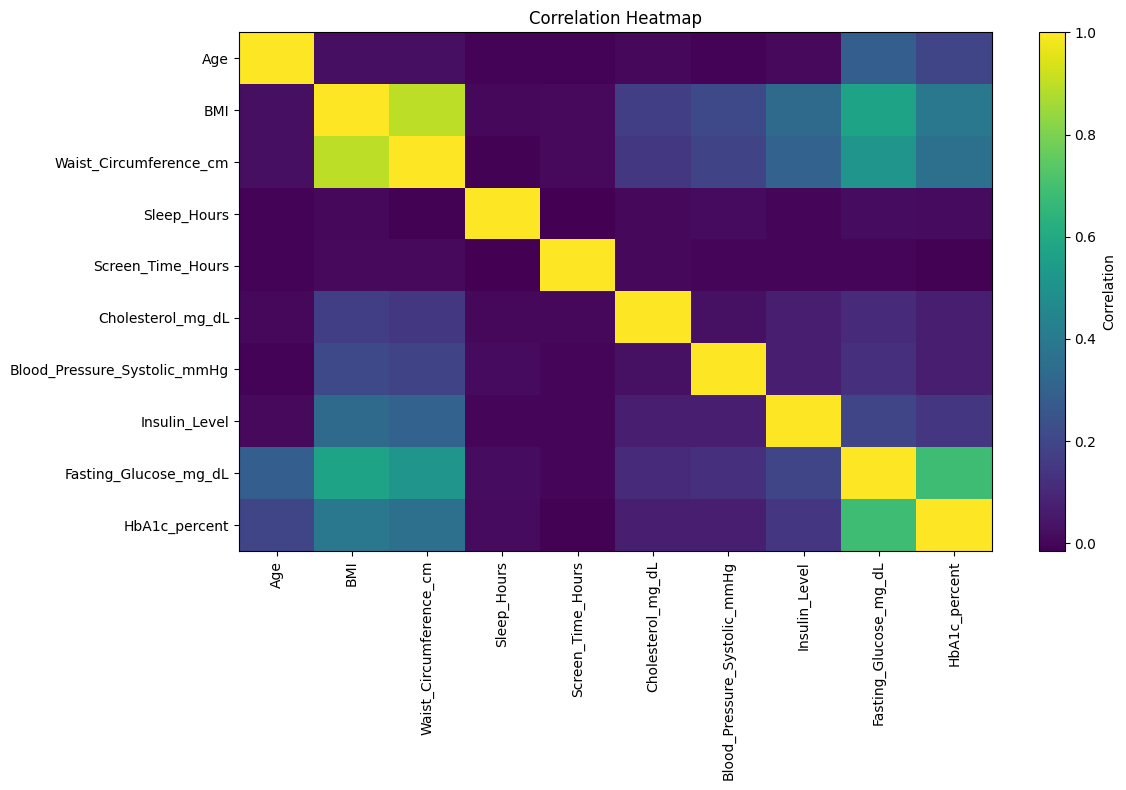

In [ ]:

# Correlation heatmap
plt.figure(figsize=(12, 8))
plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### Interpretation — Correlation heatmap (RQ4)

The highest positive associations include **BMI–Waist Circumference (r ≈ 0.90)**, **Fasting Glucose–HbA1c (r ≈ 0.69)**, and **BMI–Fasting Glucose (r ≈ 0.57)**. In contrast, **Age–BMI (r ≈ 0.03)** and **Sleep Hours–BMI (r ≈ 0.01)** show almost no *linear* association. **RQ4:** These findings explain how the numerical measurements vary together across all cleaned records; they do not prove that either variable causes changes in the other.

**Interpretation — Correlation heatmap (RQ4):** Pearson correlations in the cleaned data are approximately **r = 0.90** for BMI–Waist Circumference, **r = 0.69** for Fasting Glucose–HbA1c, **r = 0.57** for BMI–Fasting Glucose, and **r = 0.29** for Age–Fasting Glucose. Strong positive values indicate linear co-variation, not causation. They also do not show that the relationship is equally strong within both diabetes-risk groups.

In [ ]:
# Identify notable numerical correlations without reading every heatmap cell
pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
strongest_pairs = pairs.stack().sort_values(key=abs, ascending=False).head(8)
display(strongest_pairs.rename('Pearson r').round(2).to_frame())

,,Pearson r
BMI,Waist_Circumference_cm,0.90
Fasting_Glucose_mg_dL,HbA1c_percent,0.69
BMI,Fasting_Glucose_mg_dL,0.57
Waist_Circumference_cm,Fasting_Glucose_mg_dL,0.52
BMI,HbA1c_percent,0.39
Waist_Circumference_cm,HbA1c_percent,0.36
BMI,Insulin_Level,0.34
Waist_Circumference_cm,Insulin_Level,0.31


**Interpretation prompt (2c):** For each important chart, say (1) what it shows, (2) what it means for your question, (3) a limitation or alternative explanation, and (4) what to investigate next. The assessment specifically values interpretation over producing large numbers of charts.

## Stage 7 — Multivariate analysis | PRAC1 Task 2c
Multivariate analysis considers **more than two variables**. These original scatter examples use two numerical variables with diabetes-risk status as an additional grouping variable. Look for whether the relationships differ between groups.

**RQ4 focus:** Colour the scatter plots by diabetes-risk group to explore a third variable. Correlation does not imply causation and groups can overlap.


## A few multivariable views

These plots add one extra grouping variable to a scatter plot. This lets us look at a numerical relationship while also seeing the diabetes-risk groups.


### BMI vs Fasting Glucose by Diabetes Risk

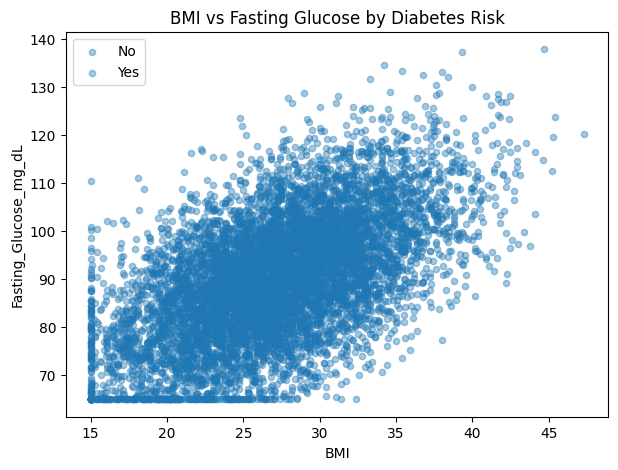

In [ ]:

no_risk = data[data["Diabetes_Risk"] == "No"]
yes_risk = data[data["Diabetes_Risk"] == "Yes"]

ax = no_risk.plot(kind="scatter", x="BMI", y="Fasting_Glucose_mg_dL", alpha=0.4, label="No", figsize=(7, 5))
yes_risk.plot(kind="scatter", x="BMI", y="Fasting_Glucose_mg_dL", alpha=0.4, label="Yes", ax=ax)
plt.title("BMI vs Fasting Glucose by Diabetes Risk")
plt.show()


### Interpretation — BMI vs Fasting Glucose coloured by risk label (RQ4)

Across the cleaned dataset, BMI and fasting glucose have a **moderate positive linear correlation (r ≈ 0.57)**. Higher BMI/glucose combinations tend to contain more `Yes` observations, but the colours overlap. **RQ4:** The graph describes a joint association, not a risk prediction rule; consider whether the risk label itself was derived from related measurements.

**RQ4 interpretation:** We now plot BMI against fasting glucose, coloured by the diabetes-risk label. Look for an upward trend and whether one group occupies more of the higher-BMI/higher-glucose region. Avoid interpreting colour separation as independent evidence if the label itself was constructed using related clinical features.

### Waist Circumference vs HbA1c by Diabetes Risk

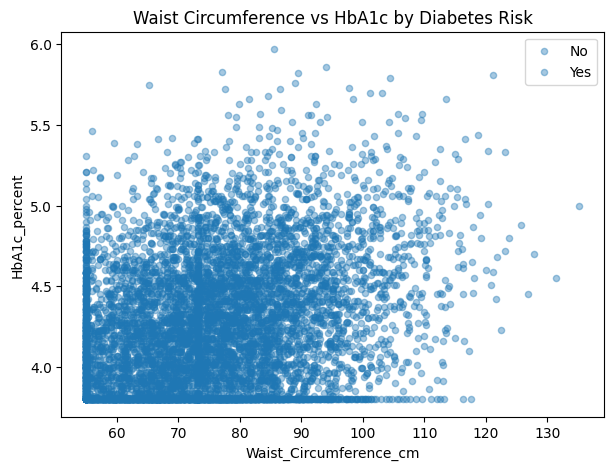

In [ ]:

no_risk = data[data["Diabetes_Risk"] == "No"]
yes_risk = data[data["Diabetes_Risk"] == "Yes"]

ax = no_risk.plot(kind="scatter", x="Waist_Circumference_cm", y="HbA1c_percent", alpha=0.4, label="No", figsize=(7, 5))
yes_risk.plot(kind="scatter", x="Waist_Circumference_cm", y="HbA1c_percent", alpha=0.4, label="Yes", ax=ax)
plt.title("Waist Circumference vs HbA1c by Diabetes Risk")
plt.show()


### Interpretation — Waist Circumference vs HbA1c coloured by risk label (RQ4)

Waist circumference and HbA1c have a **positive correlation (r ≈ 0.36)** overall. There is overlap between the `Yes` and `No` groups, and a visible concentration near the lower waist/HbA1c boundaries may influence the display. **RQ4:** The apparent separation should not be assumed to represent an independent effect of either measurement.

**RQ4 interpretation:** Waist circumference and HbA1c provide another view of body measurements and glycaemic markers. Assess whether the cloud of points changes across risk groups and whether outliers influence the apparent pattern.

### Age vs Fasting Glucose by Diabetes Risk

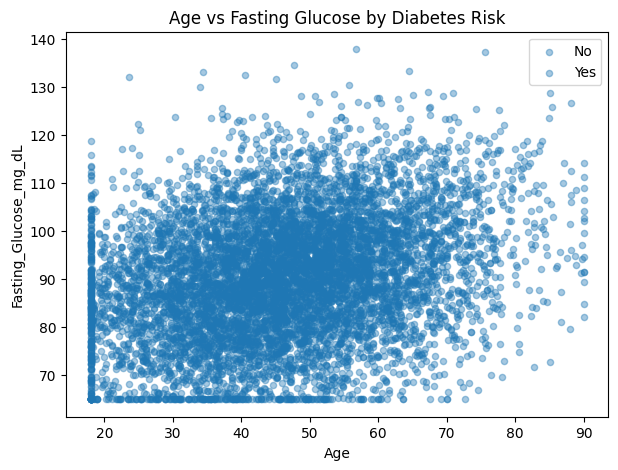

In [ ]:

no_risk = data[data["Diabetes_Risk"] == "No"]
yes_risk = data[data["Diabetes_Risk"] == "Yes"]

ax = no_risk.plot(kind="scatter", x="Age", y="Fasting_Glucose_mg_dL", alpha=0.4, label="No", figsize=(7, 5))
yes_risk.plot(kind="scatter", x="Age", y="Fasting_Glucose_mg_dL", alpha=0.4, label="Yes", ax=ax)
plt.title("Age vs Fasting Glucose by Diabetes Risk")
plt.show()


### Interpretation — Age vs Fasting Glucose coloured by risk label (RQ1/RQ4)

Age and fasting glucose show a **positive overall correlation (r ≈ 0.29)**. The `Yes` group has higher mean **Age (51.78 vs 44.39)** and **Fasting Glucose (103.86 vs 86.33 mg/dL)**, but observations overlap across the scatterplot. **RQ1/RQ4:** Compare the joint pattern, not a single cutoff; the graph does not establish a causal relationship.

**RQ1 + RQ4 interpretation:** The age-versus-glucose plot links the demographic and clinical questions. The saved group averages indicate higher age and glucose in the `Yes` group, but a scatter plot is needed to judge dispersion and overlap rather than infer a simple threshold.

## Stage 8 — Conclusions, application connection and version control | PRAC1 Tasks 3–5
The conclusions exercise below is preserved from the original notebook. Use it as a model for evidence-based reasoning, not as a ready-made conclusion.

**Assessment transfer:** Students should prioritise 3–5 meaningful hypertension findings, explain key preprocessing decisions and limitations, and decide which insights belong in a clinician-facing **Streamlit data-overview section** and **interactive-visualisation section**. The application is exploratory/educational, not a diagnostic tool. Record your changes in GitHub with clear commits.

**Our end point:** Answer the original research questions using *specific numbers*, recognise limitations, and select clear charts that could inform an exploratory Streamlit application.


## Simple conclusions

When interpreting the graphs, students should focus on questions such as:

- Which categories contain the largest or smallest number of people?
- Which numerical variables have symmetric or skewed distributions?
- Are there possible outliers?
- Which pairs of numerical variables show strong relationships?
- Do BMI and waist circumference move together?
- Do fasting glucose and HbA1c move together?
- Do people in the diabetes-risk groups show different BMI, waist circumference, glucose or HbA1c distributions?
- Does diabetes-risk percentage appear different across physical-activity or family-history groups?

### Important interpretation note
These graphs show **associations and patterns** in the dataset. They do not prove that one variable causes another variable to change.


## Answers to the four research questions — verified against the supplied CSV

The initial CSV contains **8,045 records**. After standardising gender, imputing missing values, and removing **45 exact duplicates**, the analysis uses **8,000 records**.

**RQ1 — Age and gender:** Mean age is **51.78** for `Yes` versus **44.39** for `No`. Risk-labelled percentages are **22.96% among female** and **21.86% among male** records. Age distinguishes these groups more clearly in the unadjusted summaries.

**RQ2 — Lifestyle and family history:** The percentage labelled `Yes` is **31.40% sedentary** versus **12.62% active**. With a reported family history, it is **32.52%** versus **18.13%** without one. Diet, smoking, and stress comparisons are smaller or less clear; missing categories should be interpreted separately.

**RQ3 — Clinical measurements:** The `Yes` group has higher means for **BMI (31.39 vs 25.90)**, **fasting glucose (103.86 vs 86.33 mg/dL)**, and **HbA1c (4.75% vs 4.06%)**. Histograms and box plots help assess variation and group overlap.

**RQ4 — Combined patterns:** BMI and waist circumference have **r ≈ 0.90**, while fasting glucose and HbA1c have **r ≈ 0.69**. Use risk-coloured scatter plots to evaluate whether there is overlap or visible clustering, without assuming causation.

**Outlier check:** The largest raw IQR-outlier count is `Sleep_Hours` at **47/8,045 (0.58%)**; `Fasting_Glucose_mg_dL` has **34/8,045 (0.42%)**. **No numerical column exceeds the stated 1% threshold** in this dataset. Outliers are not necessarily errors.

**Limitations:** These are unadjusted descriptive comparisons, not clinical diagnoses, causal effects or predictions. Results depend on missing-value handling, duplicate removal, group sizes and how `Diabetes_Risk` was defined.

**Assessment transfer:** For hypertension PRAC1, investigate students’ own research questions, justify preprocessing and feature engineering, interpret actual outputs, and explain any connection between blood-pressure measurements and the outcome label. The Streamlit application should support population exploration, not individual diagnosis.

### End-of-session reflection (short written responses)
1. **Research question:** Which finding answered one of your initial questions, and what new question emerged?
2. **Data handling:** Which cleaning or feature-engineering decision could change your results? Why?
3. **Visual choice:** Where was Matplotlib, Pandas plotting or Plotly most useful? Explain the choice for the audience.
4. **Clinical audience:** Which chart would you include in an interactive exploratory application, and what limitation should accompany it?

**Assessment reminder:** Students use their **hypertension** dataset, justify their choices, keep original units (no scaling), and avoid presenting BP-derived features as independent causes of a hypertension label that may be based on BP. Their final Jupyter notebook needs written interpretations, a conclusion and GitHub evidence.